# Perbandingan decision tree, SVM, ANN, dan CNN pada klasifikasi Dry Bean

In [1]:
import io
import time
import random
import urllib.request
import warnings
import zipfile
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from scipy.stats import binomtest

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.preprocessing import LabelEncoder, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

randomState = 42
random.seed(randomState)
np.random.seed(randomState)
torch.manual_seed(randomState)

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 10

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

In [2]:
import platform
import sklearn

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__}")
print(f"Platform: {platform.platform()}")

Python 3.14.6 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.0 | torch 2.14.0
Platform: macOS-27.2-arm64-arm-64bit-Mach-O


# Eksplorasi data (EDA)

dataset: Dry Bean UCI Machine Learning Repository (ID 602)

| atribut | keterangan |
|---|---|
| **nama** | Dry Bean Dataset |
| **repositori** | UCI Machine Learning Repository, Dataset ID 602 |
| **URL** | https://archive.ics.uci.edu/dataset/602/dry+bean+dataset |
| **DOI** | 10.24432/C50S4B |
| **donatur** | Murat Koklu & Ilker Ali Ozkan (2020) |
| **lisensi** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **jumlah instance** | 13.611 |
| **jumlah atribut** | 17 (16 numerik + 1 target kategorikal) |
| **missing value** | tidak ada |

variabel

| variabel | tipe | keterangan |
|---|---|---|
| `Area` | numerik | luas area biji (jumlah piksel di dalam batasnya) |
| `Perimeter` | numerik | keliling biji (panjang tepinya) |
| `MajorAxisLength` | numerik | panjang sumbu terpanjang biji |
| `MinorAxisLength` | numerik | panjang garis terpanjang yang tegak lurus sumbu utama |
| `AspectRation` | numerik | rasio `MajorAxisLength` terhadap `MinorAxisLength` (ejaan asli dataset) |
| `Eccentricity` | numerik | eksentrisitas elips yang punya momen sama dengan region biji |
| `ConvexArea` | numerik | jumlah piksel pada poligon konveks terkecil yang membungkus biji |
| `EquivDiameter` | numerik | diameter lingkaran yang luasnya sama dengan luas biji |
| `Extent` | numerik | rasio piksel biji terhadap piksel bounding box |
| `Solidity` | numerik | rasio piksel biji terhadap piksel convex hull-nya |
| `roundness` | numerik | $4\pi A / P^2$ |
| `Compactness` | numerik | `EquivDiameter` / `MajorAxisLength` |
| `ShapeFactor1` - `ShapeFactor4` | numerik | empat faktor bentuk turunan |
| `Class` | kategorikal (target) | varietas: Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira |

In [3]:
urlDataset = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
namaBerkas = "Dry_Bean_Dataset.arff"

# muat dataset dulu dari lokal, kalo gaada download dari urlDataset
def muat_dataset() -> pd.DataFrame:
    for lokasi in (Path(namaBerkas), Path("data") / namaBerkas):
        if lokasi.exists():
            print(f"Memakai berkas lokal yang sudah ada: {lokasi.name}")
            teks = lokasi.read_text()
            break
    else:
        print(f"Mengunduh dataset dari:\n  {urlDataset}")
        permintaan = urllib.request.Request(urlDataset, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(permintaan, timeout=120) as respons:
            muatan = respons.read()
        print(f"Terunduh {len(muatan):,} byte.")

        with zipfile.ZipFile(io.BytesIO(muatan)) as arsip:
            print(f"Isi arsip: {arsip.namelist()}")
            nama_arff = [n for n in arsip.namelist() if n.lower().endswith(".arff")][0]
            teks = arsip.read(nama_arff).decode("utf-8")
        print("ARFF dibaca langsung dari memori, tidak ada berkas yang ditulis ke disk.")

    data, _ = arff.loadarff(io.StringIO(teks))
    hasil = pd.DataFrame(data)
    # kolom target dari arff bisa kebaca sebagai bytes, jadi jadikan string biasa
    hasil["Class"] = hasil["Class"].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
    return hasil

df = muat_dataset()

Mengunduh dataset dari:
  https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip


Terunduh 4,738,776 byte.
Isi arsip: ['DryBeanDataset/', 'DryBeanDataset/Dry_Bean_Dataset.arff', 'DryBeanDataset/Dry_Bean_Dataset.txt', 'DryBeanDataset/Dry_Bean_Dataset.xlsx']
ARFF dibaca langsung dari memori, tidak ada berkas yang ditulis ke disk.


In [4]:
# definisikan fitur sama target
target = "Class"
fitur = [k for k in df.columns if k != target]

print(f"Dimensi  : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Fitur numerik ({len(fitur)}): {', '.join(fitur)}")
print(f"Target            : {target}")
print("\nLima baris pertama:")
df.head()

Dimensi  : 13,611 baris x 17 kolom
Fitur numerik (16): Area, Perimeter, MajorAxisLength, MinorAxisLength, AspectRation, Eccentricity, ConvexArea, EquivDiameter, Extent, Solidity, roundness, Compactness, ShapeFactor1, ShapeFactor2, ShapeFactor3, ShapeFactor4
Target            : Class

Lima baris pertama:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


struktur dataframe

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  float64
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  float64
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(16), str(1)


statistik deskriptif untuk tau sebaran data

In [6]:
deskriptif = df[fitur].describe().T
deskriptif["range"] = deskriptif["max"] - deskriptif["min"]
deskriptif["CV"] = deskriptif["std"] / deskriptif["mean"]
deskriptif["skewness"] = df[fitur].skew()
deskriptif["kurtosis"] = df[fitur].kurtosis()
deskriptif.round(4)

,count,mean,std,min,25%,50%,75%,max,range,CV,skewness,kurtosis
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000,234196.0000,0.5528,2.9529,10.8008
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700,1460.6340,0.2505,1.6261,3.5881
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602,555.2590,0.2677,1.3578,2.5319
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985,337.6858,0.2223,2.2382,6.6511
AspectRation,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303,1.4054,0.1558,0.5826,0.1138
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114,0.6925,0.1225,-1.0628,1.3875
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000,242577.0000,0.5538,2.9418,10.7436
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744,408.1306,0.2338,1.9490,5.1921
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662,0.3109,0.0655,-0.8953,0.6433
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,0.0754,0.0047,-2.5501,12.7996


skala antar-fitur sangat timpang. rata-rata `Area` sekitar 53.048 piksel sedangkan `ShapeFactor1` cuma sekitar 0,0066, jadi selisihnya beberapa orde besar. ini penting karena SVM (kernel RBF dihitung dari jarak Euclidean), ANN, dan CNN (keduanya dioptimasi dengan gradien) sensitif terhadap skala. tanpa standardisasi, fitur ukuran seperti `Area` dan `ConvexArea` bakal mendominasi hasil cuma karena angkanya besar, bukan karena lebih informatif. decision Tree tidak terpengaruh karena split-nya hanya membandingkan satu fitur dengan satu ambang.

fitur ukuran (`Area` skew 2,95, `ConvexArea` 2,94, `MinorAxisLength` 2,24) condong ke kanan, dengan nilai mean di atas median (`Area`: 53.048 vs 44.652). sedangkan `ShapeFactor4` (-2,76) dan `Solidity` (-2,55) condong ke kiri, nilainya numpuk di dekat 1. distribusinya tidak normal, tapi ini tidak jadi masalah buat tiga dari empat model yang dipakai karena tidak mengasumsikan distribusi tertentu.

cek missing value & duplikat

In [7]:
cek_data = pd.DataFrame({
    "tipe_data":      df.dtypes.astype(str),
    "jumlah_missing": df.isna().sum(),
    "nilai_unik":     df.nunique(),
})
display(cek_data)

print(f"\nTotal sel kosong di seluruh tabel : {int(df.isna().sum().sum())}")
print(f"Jumlah baris duplikat penuh       : {int(df.duplicated().sum())} ({df.duplicated().mean() * 100:.2f}%)")
print(f"Jumlah nilai negatif pada fitur   : {int((df[fitur] < 0).sum().sum())}")

,tipe_data,jumlah_missing,nilai_unik
Area,float64,0,12011
Perimeter,float64,0,13416
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRation,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,float64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13526



Total sel kosong di seluruh tabel : 0
Jumlah baris duplikat penuh       : 68 (0.50%)
Jumlah nilai negatif pada fitur   : 0


| aspek | temuan | tindakan |
|---|---|---|
| missing value | 0 sel | tidak perlu imputasi |
| tipe fitur | 16 numerik semua | tidak perlu encoding fitur |
| baris duplikat | 68 baris (0,50%) | dibuang sebelum split supaya baris yang sama tidak muncul di data latih dan data uji |
| skala fitur | beda sampai beberapa orde besar | standardisasi untuk SVM, ANN, dan CNN |

jadi data sudah cukup bersih, cleaning-nya tinggal duplikat, dan keputusan soal outlier dan multikolinearitas yang dibahas di bawah.

distribusi kelas (target)

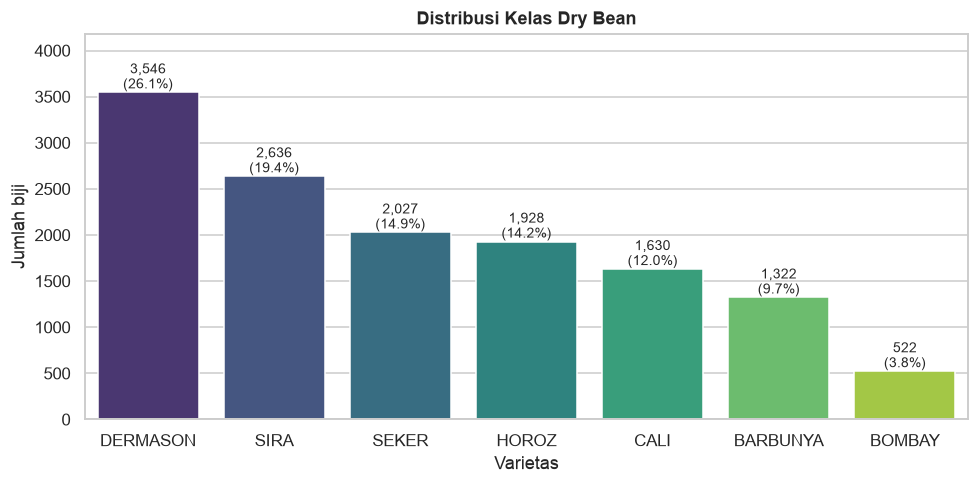

Rasio ketidakseimbangan (terbesar / terkecil): 6.79 (DERMASON vs BOMBAY)


In [8]:
urutan_kelas = df[target].value_counts().index

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x=target, order=urutan_kelas, palette="viridis", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height() / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Kelas Dry Bean")
ax.set_xlabel("Varietas")
ax.set_ylabel("Jumlah biji")
ax.set_ylim(0, df[target].value_counts().max() * 1.18)
plt.tight_layout()
plt.show()

hitung_kelas = df[target].value_counts()
print(f"Rasio ketidakseimbangan (terbesar / terkecil): {hitung_kelas.max() / hitung_kelas.min():.2f} "
      f"({hitung_kelas.idxmax()} vs {hitung_kelas.idxmin()})")

kelasnya tidak seimbang. `DERMASON` paling banyak (3.546 biji, ± 26%), `BOMBAY` paling sedikit (522 biji, ± 4%), rasionya sekitar 6,8x. ada dua konsekuensi:

- split data harus *stratified* supaya proporsi kelas terjaga di data latih dan data uji.
- akurasi saja bisa menyesatkan, jadi selain akurasi dipakai juga Precision, Recall, dan F1 rata-rata *macro* (tiap kelas bobotnya sama, jadi kelas kecil seperti `BOMBAY` tidak tenggelam).

distribusi tiap fitur

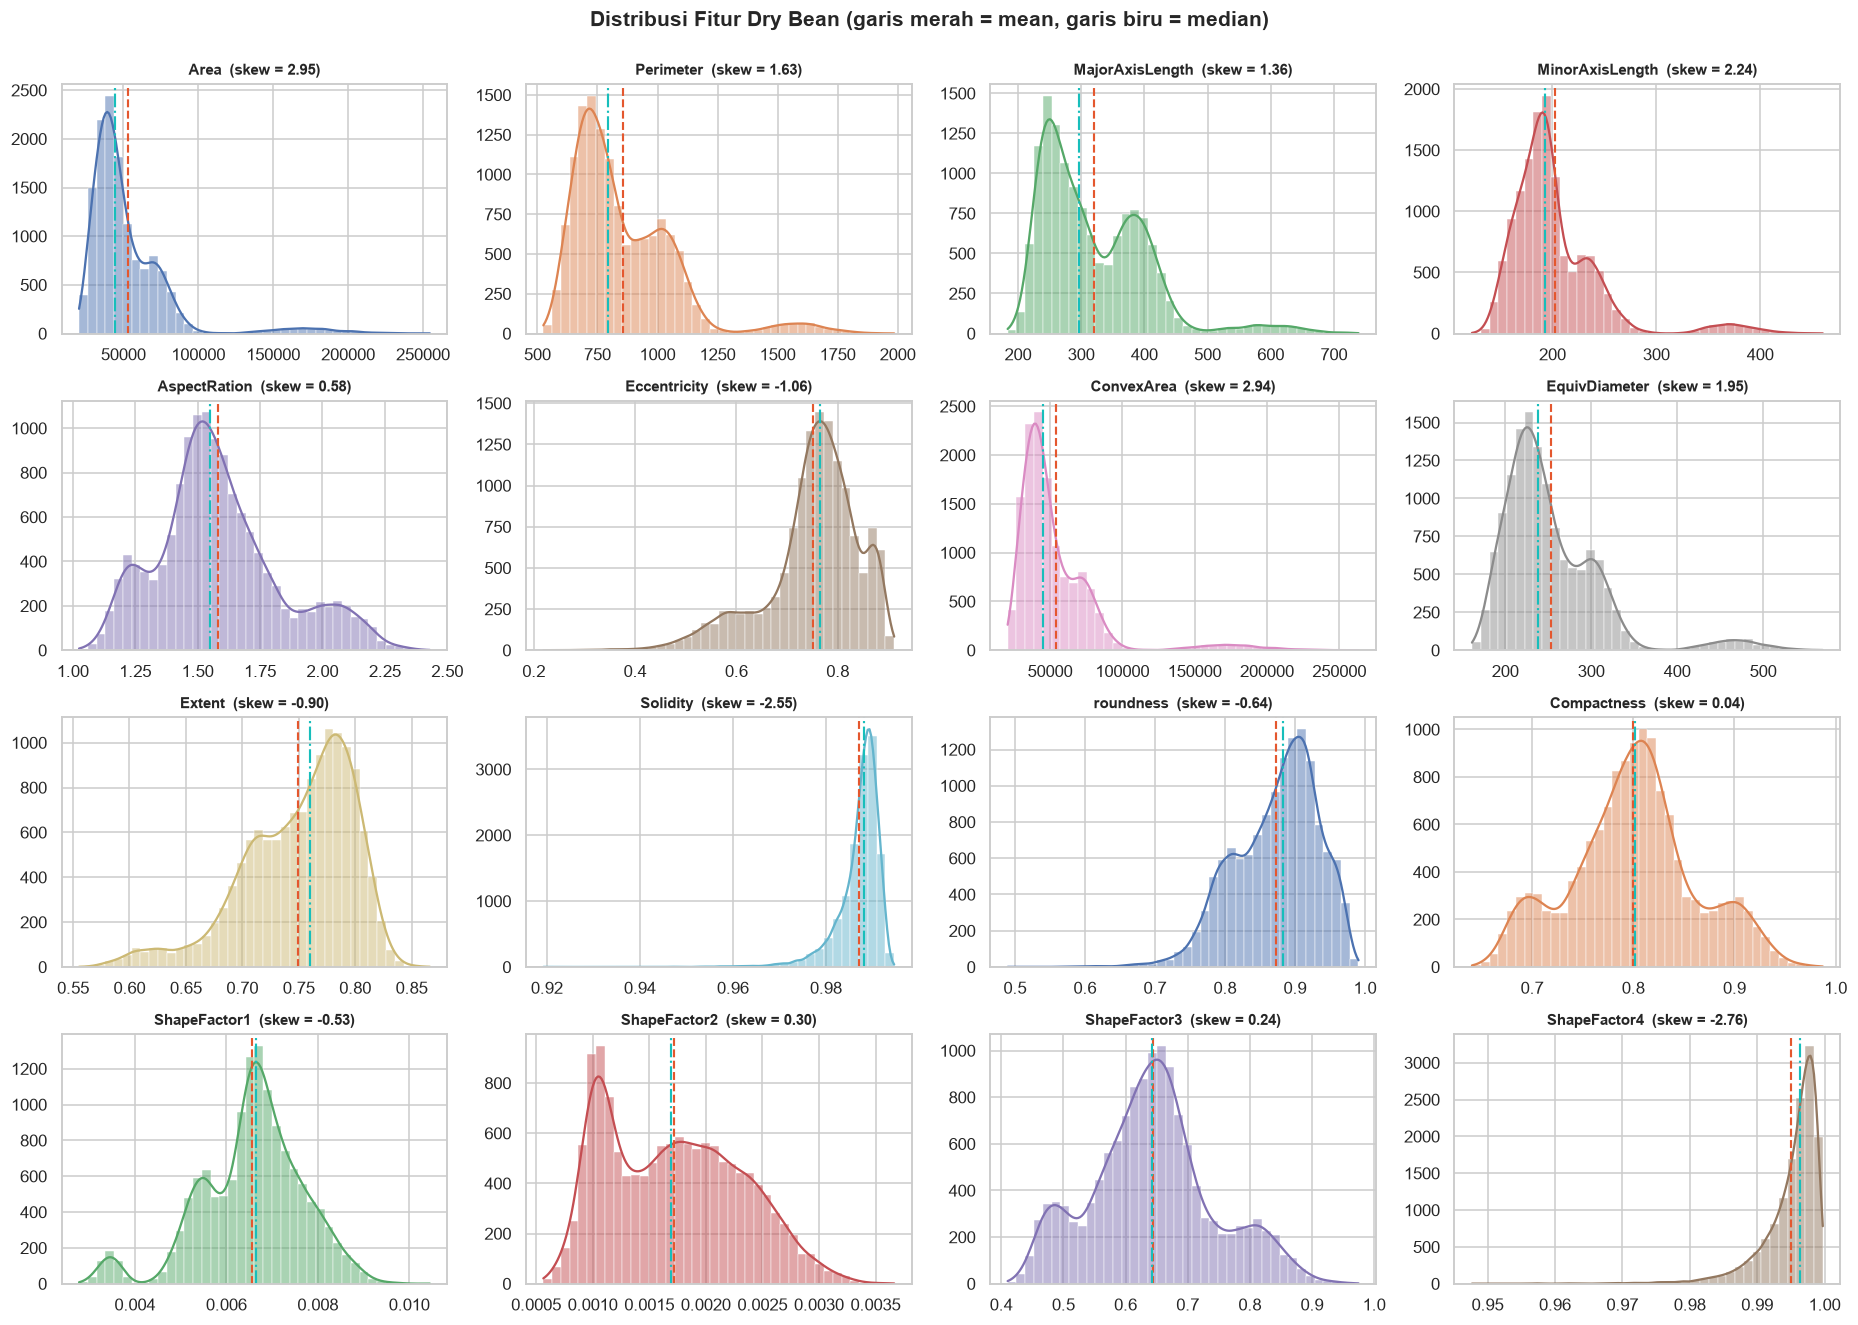

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(17, 12))
for i, (ax, kolom) in enumerate(zip(axes.ravel(), fitur)):
    sns.histplot(df[kolom], bins=40, kde=True, color=f"C{i % 10}", ax=ax,
                 edgecolor="white", linewidth=.3)
    ax.axvline(df[kolom].mean(),   color="#E4572E", ls="--", lw=1.4)
    ax.axvline(df[kolom].median(), color="#17BEBB", ls="-.", lw=1.4)
    ax.set_title(f"{kolom}  (skew = {df[kolom].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Distribusi Fitur Dry Bean (garis merah = mean, garis biru = median)",
             fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

histogram mengonfirmasi hasil `describe()` tadi. banyak fitur punya lebih dari satu puncak (misalnya `Perimeter`, `MajorAxisLength`, `ShapeFactor3`), dan ini wajar karena datanya campuran 7 varietas dengan ukuran berbeda. kelompok kecil di sisi kanan `Area` dan `ConvexArea` (di atas 150.000 piksel) kemungkinan besar adalah `BOMBAY`, yang bijinya jauh lebih besar. ini dicek lagi di bawah.

outlier dengan metode IQR

In [10]:
def deteksi_outlier_iqr(data: pd.DataFrame, kolom: list[str], pengali: float = 1.5) -> pd.DataFrame:
    baris = []
    for k in kolom:
        q1, q3 = data[k].quantile(.25), data[k].quantile(.75)
        iqr = q3 - q1
        bawah, atas = q1 - pengali * iqr, q3 + pengali * iqr
        di_luar = (data[k] < bawah) | (data[k] > atas)
        baris.append({
            "variabel": k, "Q1": q1, "Q3": q3, "IQR": iqr,
            "batas_bawah": bawah, "batas_atas": atas,
            "n_outlier": int(di_luar.sum()),
            "persen_outlier": round(di_luar.mean() * 100, 2),
        })
    return pd.DataFrame(baris).set_index("variabel")

ringkas_outlier = deteksi_outlier_iqr(df, fitur)
display(ringkas_outlier.sort_values("persen_outlier", ascending=False).round(3))

# tandai sel mana saja yang outlier, lalu hitung berapa BARIS yang kena
mask_outlier = pd.DataFrame(False, index=df.index, columns=fitur)
for k in fitur:
    bawah, atas = ringkas_outlier.loc[k, ["batas_bawah", "batas_atas"]]
    mask_outlier[k] = (df[k] < bawah) | (df[k] > atas)

baris_terdampak = mask_outlier.any(axis=1).sum()
print(f"\nBaris dengan >=1 outlier : {baris_terdampak:,} dari {len(df):,} ({baris_terdampak / len(df) * 100:.1f}%)")

,Q1,Q3,IQR,batas_bawah,batas_atas,n_outlier,persen_outlier
variabel,,,,,,,
Eccentricity,0.716,0.810,0.095,0.574,0.952,843,6.19
Solidity,0.986,0.990,0.004,0.979,0.997,778,5.72
ShapeFactor4,0.994,0.998,0.004,0.987,1.004,767,5.64
MinorAxisLength,175.848,217.032,41.184,114.073,278.807,569,4.18
Area,36328.000,61332.000,25004.000,-1178.000,98838.000,551,4.05
ConvexArea,36714.500,62294.000,25579.500,-1654.750,100663.250,550,4.04
ShapeFactor1,0.006,0.007,0.001,0.004,0.009,533,3.92
EquivDiameter,215.068,279.446,64.378,118.500,376.014,526,3.86
Perimeter,703.523,977.213,273.690,292.989,1387.747,500,3.67



Baris dengan >=1 outlier : 3,017 dari 13,611 (22.2%)


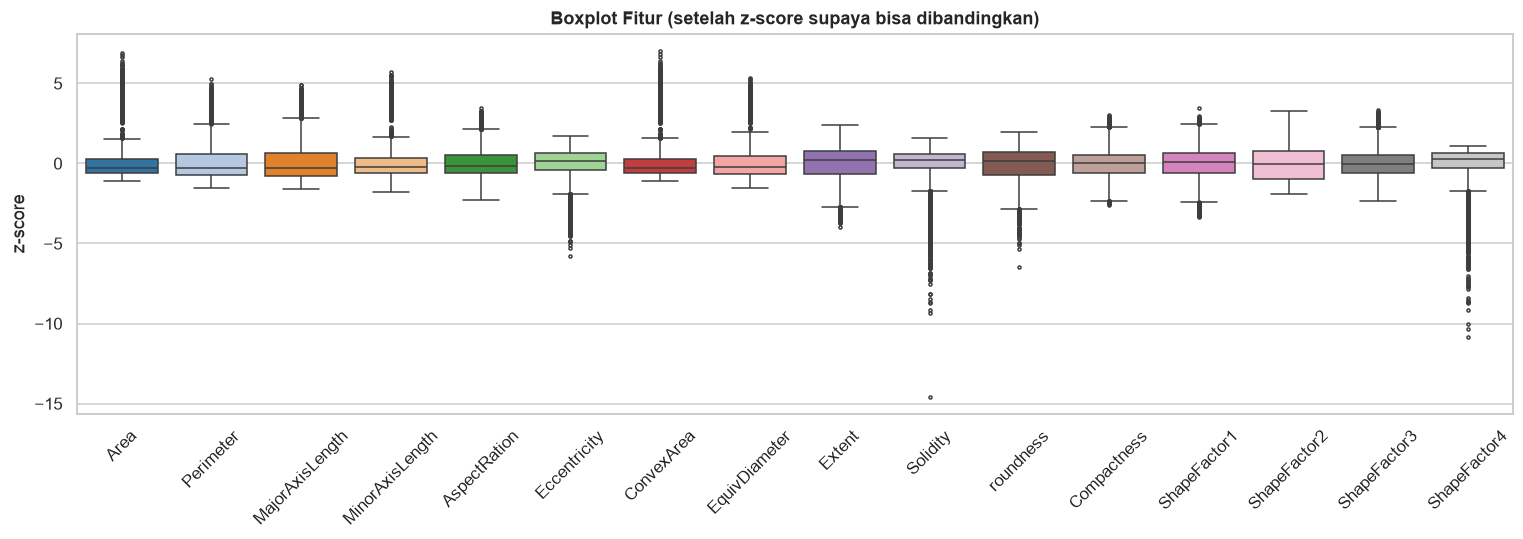

Persentase baris dengan >=1 outlier (IQR global) per kelas:


,persen_baris_outlier
Class,
BOMBAY,100.0
HOROZ,44.7
SEKER,41.4
CALI,24.8
BARBUNYA,19.0
DERMASON,2.3
SIRA,2.0


In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
z_score = (df[fitur] - df[fitur].mean()) / df[fitur].std()
sns.boxplot(data=z_score, ax=ax, palette="tab20", fliersize=2, linewidth=1)
ax.set_title("Boxplot Fitur (setelah z-score supaya bisa dibandingkan)")
ax.set_ylabel("z-score")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# outlier ini sebenarnya ngumpul di kelas mana?
per_kelas = mask_outlier.any(axis=1).groupby(df[target]).mean().sort_values(ascending=False) * 100
print("Persentase baris dengan >=1 outlier (IQR global) per kelas:")
display(per_kelas.round(1).to_frame("persen_baris_outlier"))

sekitar 22% baris punya minimal satu outlier, dan paling banyak di `Eccentricity` (6,19%), `Solidity` (5,72%), dan `ShapeFactor4` (5,64%).

tapi outlier-nya ngumpul di kelas tertentu. semua baris `BOMBAY` (100%) punya outlier, lalu `HOROZ` (44,7%) dan `SEKER` (41,4%), sedangkan `DERMASON` (2,3%) dan `SIRA` (2,0%) hampir tidak ada. artinya "outlier" menurut IQR global ini sebagian besar bukan kesalahan ukur, tapi biji dari varietas yang memang berukuran atau berbentuk beda dari mayoritas.

keputusannya outlier **tidak dibuang dan tidak di-capping**:

- datanya hasil ukur fisik dari gambar, nilai ekstrem adalah biji yang memang besar/kecil.
- kalau dibuang, kelas `BOMBAY` (kelas minoritas) bakal hilang hampir seluruhnya, padahal ciri pembedanya justru ukurannya yang ekstrem.
- model yang dipakai cukup tahan: pohon membagi dengan ambang (tidak terpengaruh seberapa jauh nilai ekstremnya), sedangkan SVM RBF, ANN, dan CNN dibantu standardisasi.

korelasi antar fitur

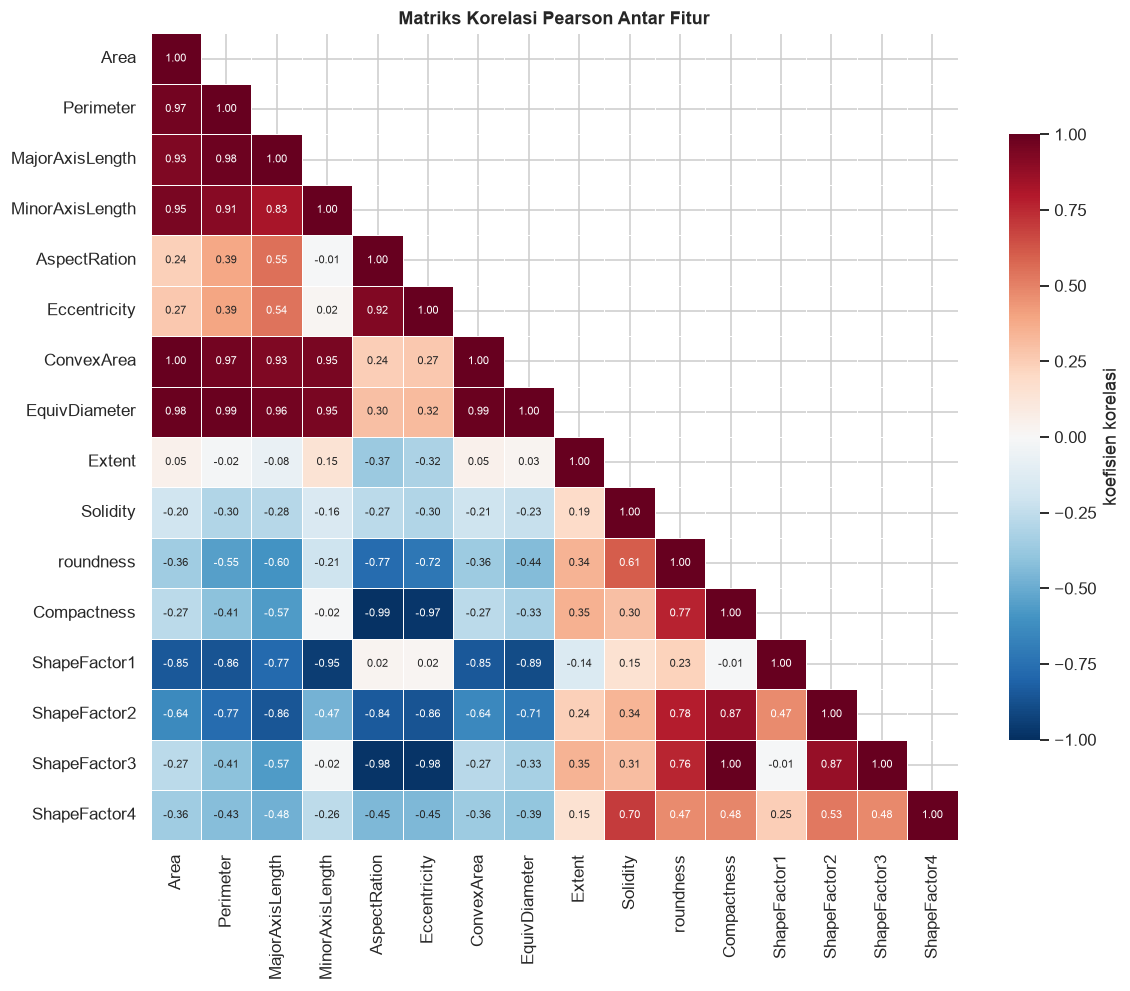

Jumlah pasangan fitur dengan |r| >= 0.95 : 15


,fitur_1,fitur_2,korelasi_pearson
0,Area,ConvexArea,0.9999
1,Compactness,ShapeFactor3,0.9987
2,Perimeter,EquivDiameter,0.9914
3,AspectRation,Compactness,-0.9877
4,ConvexArea,EquivDiameter,0.9852
5,Area,EquivDiameter,0.9850
6,Eccentricity,ShapeFactor3,-0.9811
7,AspectRation,ShapeFactor3,-0.9786


In [12]:
korelasi = df[fitur].corr()
mask = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, annot_kws={"size": 7},
            cbar_kws={"shrink": .75, "label": "koefisien korelasi"}, ax=ax)
ax.set_title("Matriks Korelasi Pearson Antar Fitur")
plt.tight_layout()
plt.show()

# pasangan dengan korelasi terkuat
pasangan = korelasi.where(mask).stack().reset_index()
pasangan.columns = ["fitur_1", "fitur_2", "korelasi_pearson"]
pasangan = pasangan.reindex(pasangan.korelasi_pearson.abs().sort_values(ascending=False).index)
print(f"Jumlah pasangan fitur dengan |r| >= 0.95 : {(pasangan.korelasi_pearson.abs() >= .95).sum()}")
display(pasangan.head(8).reset_index(drop=True).round(4))

banyak fitur yang berkorelasi sangat kuat, 15 pasangan dengan |r| >= 0,95. yang paling ekstrem `Area` dengan `ConvexArea` (r = 0,9999), lalu `Compactness` dengan `ShapeFactor3` (0,9987), dan `Perimeter` dengan `EquivDiameter` (0,9914). wajar, karena semua fitur ini dihitung dari dimensi biji yang sama.

implikasinya ke tiap model:

- **decision tree** tidak terganggu, tiap split cuma pilih satu fitur, fitur kembarannya akan berbagi nilai *importance*.
- **SVM, ANN, CNN** tetap bisa dilatih, redundansinya cuma menambah dimensi tanpa informasi baru.
- Ke-16 fitur tetap dipakai semua supaya perbandingan antar metode adil dan tidak ada metode yang diuntungkan oleh seleksi fitur tertentu.

apakah fitur bisa membedakan kelas?

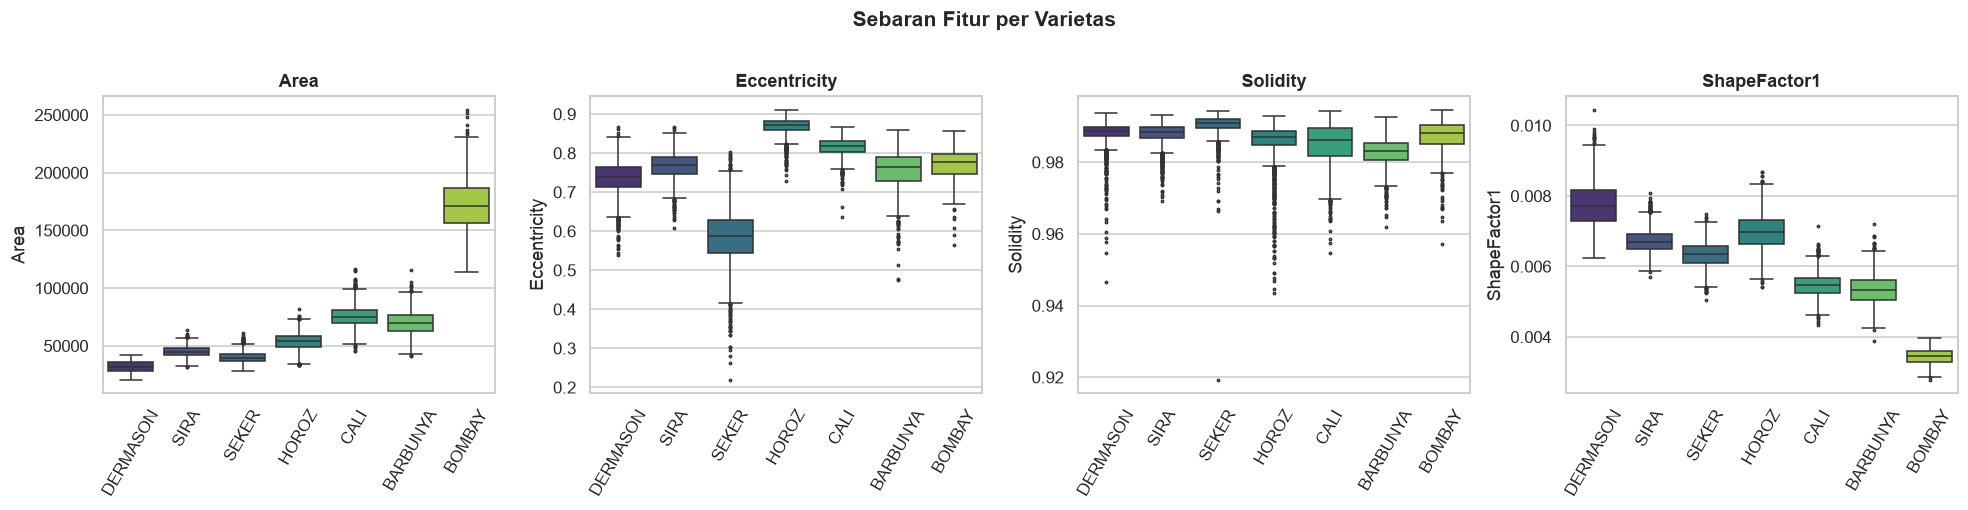

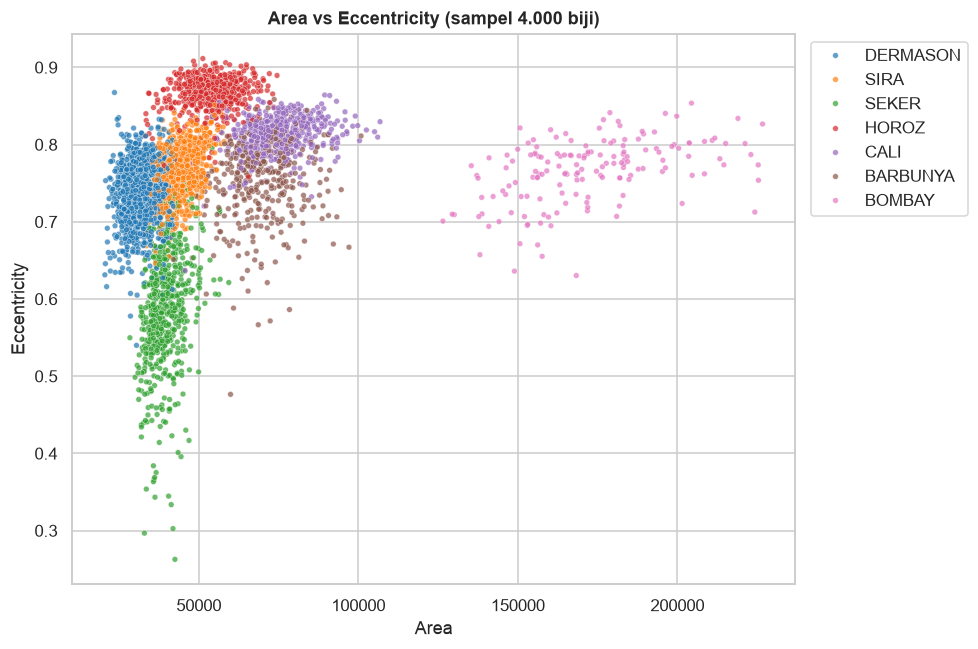

,Area,Eccentricity,Solidity,ShapeFactor1
Class,,,,
BARBUNYA,69582.0,0.7633,0.9831,0.0053
BOMBAY,171494.5,0.7763,0.9881,0.0035
CALI,74791.5,0.8169,0.9862,0.0055
DERMASON,31890.0,0.7392,0.9887,0.0077
HOROZ,53800.5,0.8711,0.9870,0.0070
SEKER,39180.0,0.5879,0.9909,0.0064
SIRA,44593.0,0.7683,0.9885,0.0067


In [13]:
fitur_contoh = ["Area", "Eccentricity", "Solidity", "ShapeFactor1"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, kolom in zip(axes, fitur_contoh):
    sns.boxplot(data=df, x=target, y=kolom, order=urutan_kelas, palette="viridis", fliersize=1.5, ax=ax)
    ax.set_title(kolom)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Sebaran Fitur per Varietas", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df.sample(4000, random_state=randomState), x="Area", y="Eccentricity",
                hue=target, hue_order=urutan_kelas, palette="tab10", s=14, alpha=.7, ax=ax)
ax.set_title("Area vs Eccentricity (sampel 4.000 biji)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(df.groupby(target)[["Area", "Eccentricity", "Solidity", "ShapeFactor1"]].median().round(4))

`BOMBAY` gampang dipisah, median `Area`-nya 171.494,5, jauh di atas kelas lain yang maksimal sekitar 75.000. tapi kelas lain saling tumpang tindih di hampir semua fitur, terutama `SIRA` dengan `DERMASON` (median `Area` 44.593 vs 31.890, `Solidity` dan `ShapeFactor1` juga hampir sama). jadi diperkirakan kesalahan klasifikasi bakal numpuk di pasangan kelas yang mirip ini, dan nanti dicek lewat *confusion matrix*.

ringkasan temuan EDA

| aspek | temuan | tindakan |
|---|---|---|
| missing value | tidak ada | tidak ada |
| duplikat | 68 baris | dibuang |
| skala fitur | beda beberapa orde besar | standardisasi (SVM, ANN, CNN) |
| outlier | 22% baris, ngumpul di kelas besar/berbentuk beda (`BOMBAY` 100%) | dipertahankan |
| multikolinearitas | 15 pasang fitur dengan \|r\| >= 0,95 | dipertahankan agar adil antar metode |
| keseimbangan kelas | rasio 6,8x | split *stratified* dan metrik *macro* |

# Data cleaning & preprocessing

langkah yang dilakukan:

1. buang baris duplikat.
2. *label-encode* target (7 kelas menjadi 0 sampai 6).
3. bagi data **80% latih / 20% uji** secara *stratified*. data uji tidak disentuh sampai evaluasi akhir.
4. standardisasi (`StandardScaler`) yang di-*fit* **hanya pada data latih**.

decision tree dilatih dengan data mentah karena tidak butuh scaling. SVM dan ANN memakai `Pipeline` (`StandardScaler` lalu model), jadi pada saat *cross-validation* scaler cuma belajar dari lipatan latih dan tidak ada kebocoran dari lipatan validasi. CNN memakai data yang sudah distandardisasi.

In [14]:
# buang duplikat dulu sebelum split
df_bersih = df.drop_duplicates().reset_index(drop=True)
print(f"Sebelum : {len(df):,} baris")
print(f"Sesudah : {len(df_bersih):,} baris (dibuang {len(df) - len(df_bersih)} duplikat)")

# encoding target
le = LabelEncoder()
y = le.fit_transform(df_bersih[target])
X = df_bersih[fitur].values.astype(np.float32)
kelas = list(le.classes_)
print("\nPemetaan kelas:", dict(zip(range(len(kelas)), kelas)))

Sebelum : 13,611 baris
Sesudah : 13,543 baris (dibuang 68 duplikat)

Pemetaan kelas: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


In [15]:
# split 80/20, stratify supaya proporsi kelas sama di kedua bagian
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=randomState
)
print(f"Data latih : {X_latih.shape}")
print(f"Data uji   : {X_uji.shape}")

proporsi = pd.DataFrame({
    "latih (%)": pd.Series(y_latih).value_counts(normalize=True).sort_index() * 100,
    "uji (%)":   pd.Series(y_uji).value_counts(normalize=True).sort_index() * 100,
})
proporsi.index = kelas
print("\nProporsi kelas (harus mirip antar split):")
display(proporsi.round(2))

# skema cross-validation untuk tuning hyperparameter, dipakai bareng semua model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=randomState)

Data latih : (10834, 16)
Data uji   : (2709, 16)

Proporsi kelas (harus mirip antar split):


,latih (%),uji (%)
BARBUNYA,9.76,9.78
BOMBAY,3.86,3.84
CALI,12.04,12.03
DERMASON,26.19,26.17
HOROZ,13.73,13.73
SEKER,14.96,14.99
SIRA,19.47,19.45


proporsi kelas di data latih dan data uji hampir identik, jadi split-nya sudah stratified dengan benar. skema 5-fold stratified (`cv`) dipakai untuk memilih hyperparameter pada data latih saja.

kenapa standardisasi perlu?

di EDA tadi dibilang SVM dan ANN sensitif terhadap skala, sedangkan Decision Tree tidak. klaim ini dites langsung, hanya di data latih (5-fold CV), membandingkan tiap model tanpa dan dengan `StandardScaler`. konfigurasi modelnya sama dengan yang nanti terpilih di bagian implementasi, jadi cuma ada satu perbedaan, yaitu scaler.

In [16]:
model_uji_skala = {
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", max_depth=10, min_samples_leaf=10, random_state=randomState),
    "SVM": SVC(kernel="rbf", C=10, gamma="scale", random_state=randomState),
    "ANN (MLP)": MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-4, learning_rate_init=5e-3, early_stopping=True,
                               n_iter_no_change=15, max_iter=500, random_state=randomState),
}

baris = []
for nama, m in model_uji_skala.items():
    tanpa_scaler = cross_val_score(m, X_latih, y_latih, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    dengan_scaler = cross_val_score(Pipeline([("scaler", StandardScaler()), ("model", m)]),
                                    X_latih, y_latih, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    baris.append({"Model": nama, "F1-macro CV tanpa scaler": tanpa_scaler,
                  "F1-macro CV dengan StandardScaler": dengan_scaler, "selisih": dengan_scaler - tanpa_scaler})

display(pd.DataFrame(baris).set_index("Model").round(4))

,F1-macro CV tanpa scaler,F1-macro CV dengan StandardScaler,selisih
Model,,,
Decision Tree,0.9270,0.9265,-0.0004
SVM,0.5854,0.9438,0.3584
ANN (MLP),0.4745,0.9440,0.4694


klaimnya terbukti. tanpa scaler, F1 macro SVM cuma 0,5854 dan ANN 0,4745, sedangkan dengan `StandardScaler` keduanya naik jadi 0,9438 dan 0,9440 (selisih +0,36 dan +0,47). penyebabnya fitur berskala besar seperti `Area` (puluhan ribu) mendominasi jarak pada kernel RBF dan gradien pada MLP, sedangkan fitur bentuk seperti `ShapeFactor1` (sekitar 0,006) hampir tidak berpengaruh.

decision tree praktis tidak terpengaruh (0,9270 tanpa scaler vs 0,9265 dengan scaler). selisih -0,0004 itu kemungkinan cuma efek pembulatan floating point pada ambang split, karena pohon hanya membandingkan satu fitur dengan satu ambang sehingga skala fitur tidak berarti baginya. jadi standardisasi memang wajib untuk SVM, ANN, dan CNN, tapi tidak untuk Decision Tree.

# Implementasi supervised learning

metrik evaluasi yang digunakan:

1. **akurasi** proporsi prediksi yang benar dari seluruh data uji.

2. **precision (macro)** dari semua biji yang diprediksi kelas tertentu, berapa yang benar-benar kelas itu, lalu dirata-rata antar kelas (bobot kelas sama).

3. **recall (macro)** dari semua biji yang aslinya kelas tertentu, berapa yang berhasil terdeteksi, dirata-rata antar kelas.

4. **F1-Score (macro)** rata-rata harmonik Precision dan Recall per kelas, lalu dirata-rata. juga dilaporkan F1 *weighted* (dibobot jumlah sampel per kelas).

karena kelasnya tidak seimbang, F1 macro dijadikan skor utama untuk tuning hyperparameter (`GridSearchCV`, 5-fold) dan untuk mengurutkan hasil. model terbaik otomatis di-*refit* pada seluruh data latih lalu diuji **sekali** pada data uji.

In [17]:
hasilEvaluasi, prediksi = {}, {}

def evaluasi_model(nama: str, y_asli: np.ndarray, y_pred: np.ndarray, waktu_latih: float, param=None) -> None:
    '''Hitung metrik evaluasi, simpan ke hasilEvaluasi, dan cetak laporan per kelas.'''
    hasil = {
        "Akurasi":           accuracy_score(y_asli, y_pred),
        "Precision (macro)": precision_score(y_asli, y_pred, average="macro"),
        "Recall (macro)":    recall_score(y_asli, y_pred, average="macro"),
        "F1 (macro)":        f1_score(y_asli, y_pred, average="macro"),
        "F1 (weighted)":     f1_score(y_asli, y_pred, average="weighted"),
        "Waktu latih (s)":   waktu_latih,
    }
    hasilEvaluasi[nama] = hasil
    prediksi[nama] = np.asarray(y_pred)

    if param:
        print("Hyperparameter terbaik:", param)
    print(pd.Series(hasil).round(4).to_string(), "\n")
    print(classification_report(y_asli, y_pred, target_names=kelas, digits=4))


def gambar_cm(nama: str, y_asli: np.ndarray, y_pred: np.ndarray) -> None:
    '''Confusion matrix: jumlah dan versi dinormalisasi per kelas asli (= recall).'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax, norm, judul in zip(axes, [None, "true"], ["Jumlah", "Dinormalisasi per kelas asli (= recall)"]):
        ConfusionMatrixDisplay.from_predictions(
            y_asli, y_pred, display_labels=kelas, normalize=norm, cmap="Blues",
            values_format=".2f" if norm else "d", colorbar=False, ax=ax)
        ax.set_title(f"{nama}: {judul}")
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


def ringkas_tuning(gs: GridSearchCV, teratas: int = 8) -> pd.DataFrame:
    kolom = ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    tabel = pd.DataFrame(gs.cv_results_)[kolom].sort_values("rank_test_score").head(teratas)
    tabel["params"] = tabel["params"].astype(str).str.replace("classifier__", "")
    return tabel.reset_index(drop=True).round(4)

decision tree

pohon keputusan membagi data secara rekursif dengan aturan `fitur <= ambang`. tanpa pembatasan, pohon cenderung menghafal data latih (*overfit*), jadi yang dicari lewat grid adalah kombinasi `criterion` (`gini` atau `entropy`), `max_depth`, dan `min_samples_leaf`.

In [18]:
grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 14, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
}

t0 = time.perf_counter()
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=randomState), grid_dt,
                     cv=cv, scoring="f1_macro", n_jobs=-1)
gs_dt.fit(X_latih, y_latih)
waktu_tuning_dt = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktu_tuning_dt:.1f} s ({len(gs_dt.cv_results_['params'])} kombinasi x 5 fold)")
print(f"F1-macro CV terbaik : {gs_dt.best_score_:.4f}")
print(f"Hyperparameter      : {gs_dt.best_params_}")
display(ringkas_tuning(gs_dt))

Grid search selesai dalam 3.1 s (60 kombinasi x 5 fold)
F1-macro CV terbaik : 0.9270
Hyperparameter      : {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}",0.9270,0.0072,1
1,"{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 10}",0.9260,0.0072,2
2,"{'criterion': 'entropy', 'max_depth': 14, 'min_samples_leaf': 10}",0.9257,0.0068,3
3,"{'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 10}",0.9246,0.0071,4
4,"{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5}",0.9240,0.0067,5
5,"{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 10}",0.9238,0.0066,6
6,"{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 5}",0.9234,0.0044,7
7,"{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 10}",0.9234,0.0068,8


Hyperparameter terbaik: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}
Akurasi              0.9022
Precision (macro)    0.9141
Recall (macro)       0.9126
F1 (macro)           0.9132
F1 (weighted)        0.9021
Waktu latih (s)      0.0778 

              precision    recall  f1-score   support

    BARBUNYA     0.8529    0.8755    0.8641       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9012    0.8957    0.8985       326
    DERMASON     0.8907    0.9196    0.9049       709
       HOROZ     0.9637    0.9274    0.9452       372
       SEKER     0.9317    0.9409    0.9363       406
        SIRA     0.8585    0.8292    0.8436       527

    accuracy                         0.9022      2709
   macro avg     0.9141    0.9126    0.9132      2709
weighted avg     0.9024    0.9022    0.9021      2709

Kedalaman pohon : 10 | jumlah daun : 197


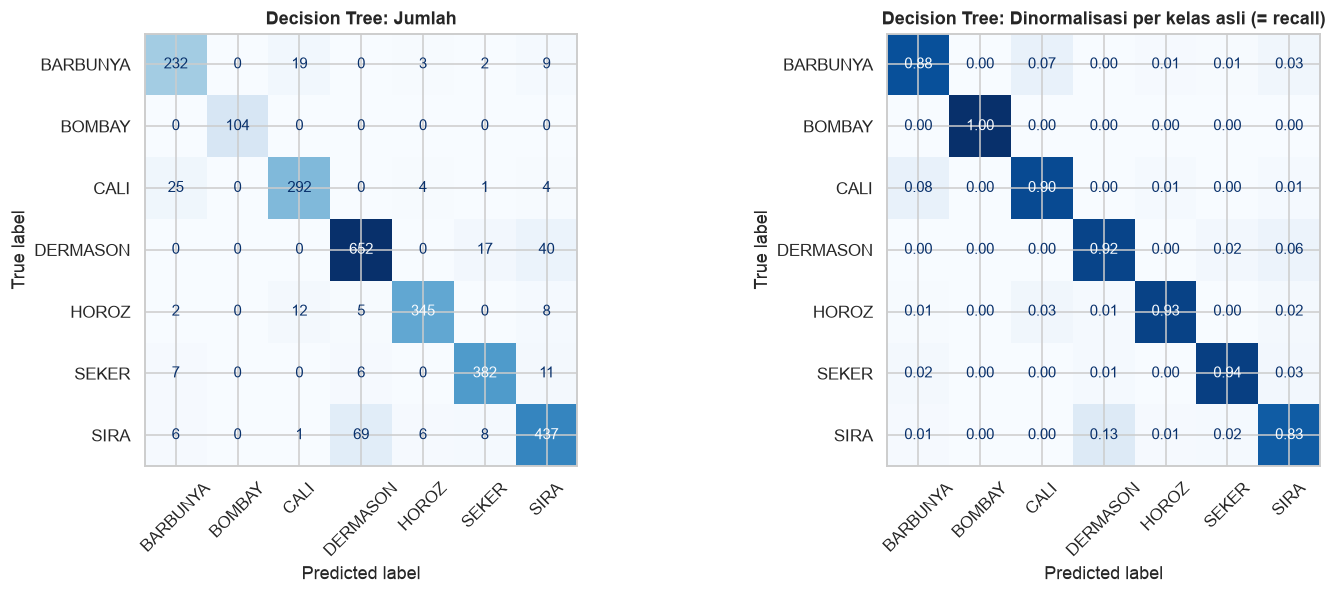

In [19]:
model_dt = gs_dt.best_estimator_

# latih ulang satu model dengan hyperparameter terbaik untuk ukur waktu latih
t0 = time.perf_counter()
model_dt.fit(X_latih, y_latih)
waktu_dt = time.perf_counter() - t0

pred_dt = model_dt.predict(X_uji)
evaluasi_model("Decision Tree", y_uji, pred_dt, waktu_dt, gs_dt.best_params_)
print(f"Kedalaman pohon : {model_dt.get_depth()} | jumlah daun : {model_dt.get_n_leaves()}")
gambar_cm("Decision Tree", y_uji, pred_dt)

pohon terbaik memakai `entropy`, `max_depth=10`, dan `min_samples_leaf=10` (197 daun). akurasi di data uji 0,9022 dan F1 macro 0,9132. `BOMBAY` benar semua (F1 = 1,00), sedangkan kelas terlemahnya `SIRA` (F1 0,8436) dan `BARBUNYA` (0,8641).

kelebihan utama Decision Tree adalah bisa dibaca. di bawah ini ditampilkan 3 level teratas pohon dan *feature importance*-nya.

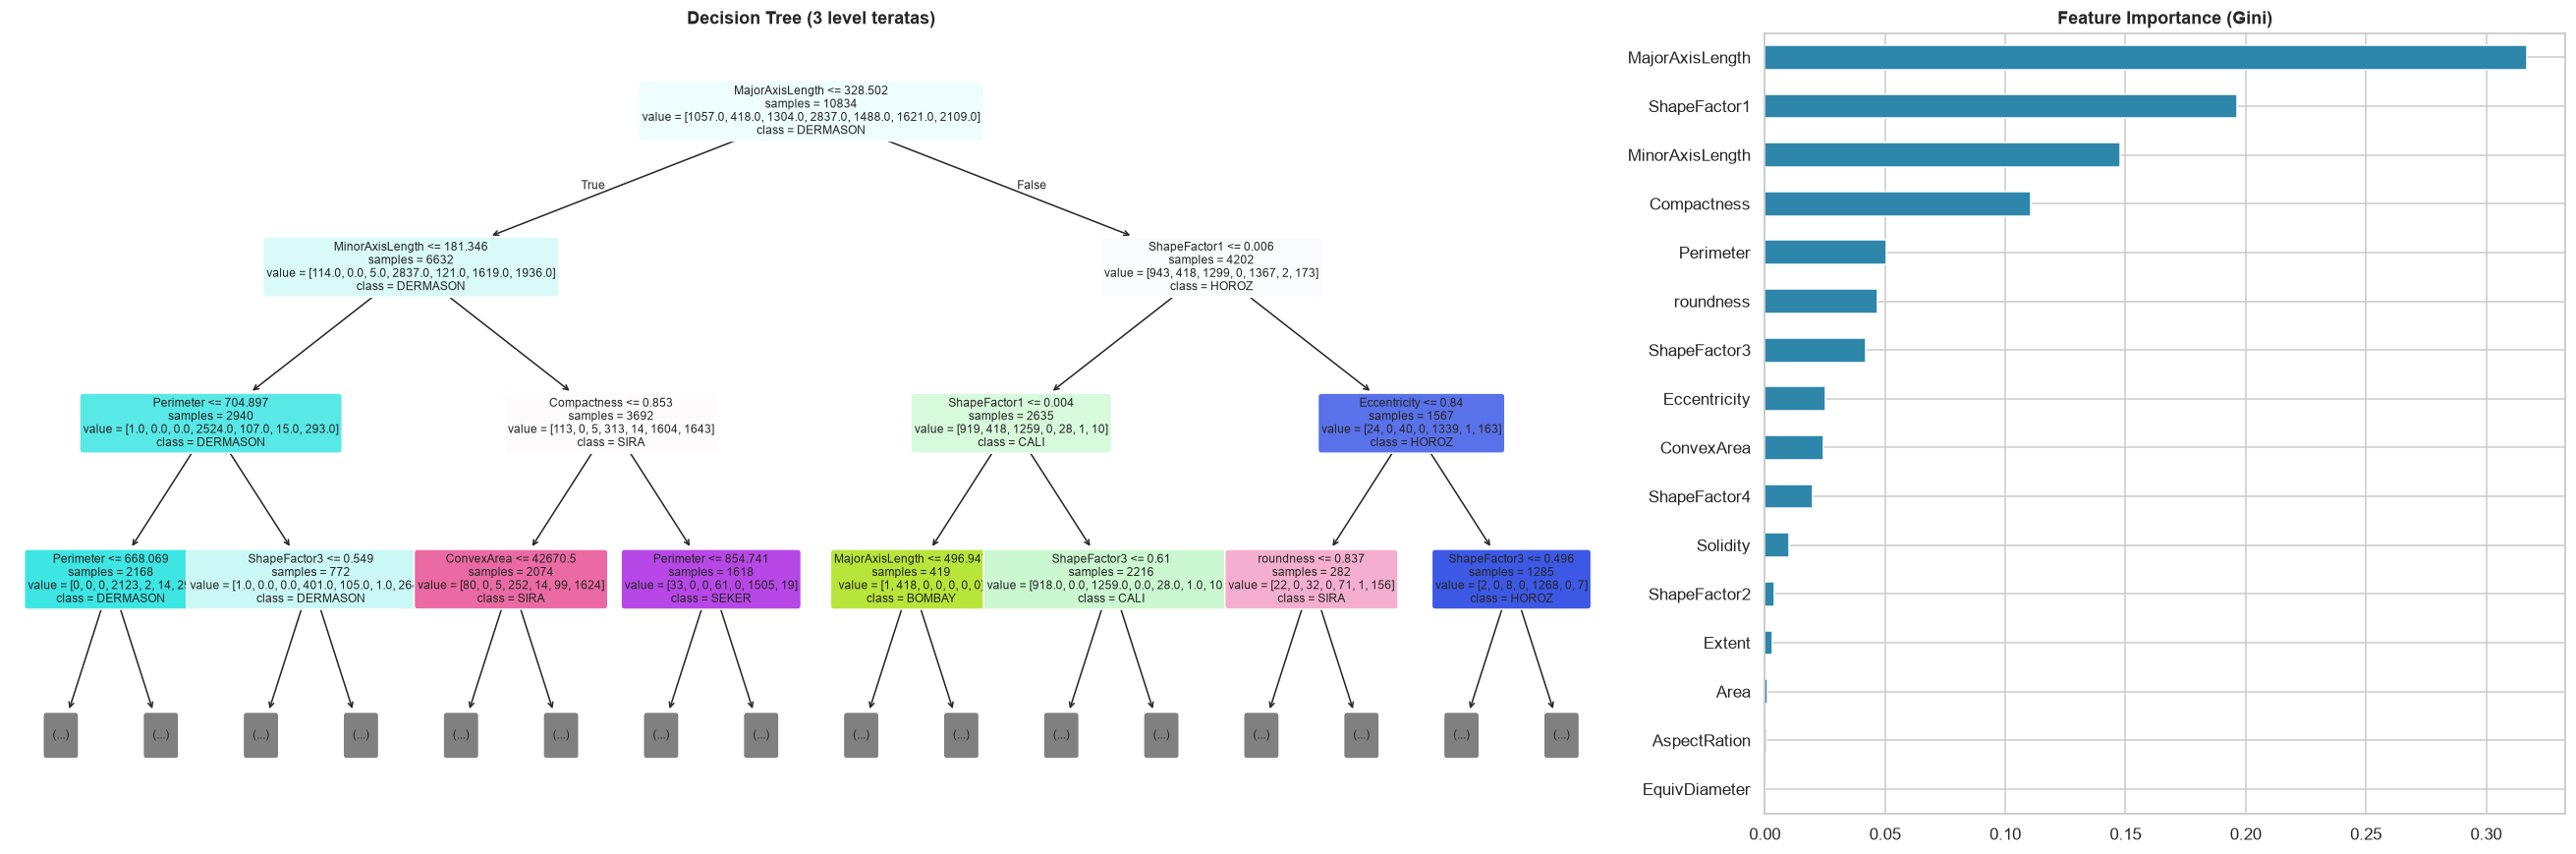

5 fitur terpenting: MajorAxisLength, ShapeFactor1, MinorAxisLength, Compactness, Perimeter


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(24, 8), gridspec_kw={"width_ratios": [2, 1]})
plot_tree(model_dt, max_depth=3, feature_names=fitur, class_names=kelas, filled=True,
          rounded=True, fontsize=8, impurity=False, ax=axes[0])
axes[0].set_title("Decision Tree (3 level teratas)")

pentingnya = pd.Series(model_dt.feature_importances_, index=fitur).sort_values()
pentingnya.plot.barh(ax=axes[1], color="#2E86AB")
axes[1].set_title("Feature Importance (Gini)")
plt.tight_layout()
plt.show()

print("5 fitur terpenting:", ", ".join(pentingnya.sort_values(ascending=False).head(5).index))

split paling atas memakai `MajorAxisLength`, lalu `MinorAxisLength` dan `ShapeFactor1`. lima fitur terpenting adalah `MajorAxisLength`, `ShapeFactor1`, `MinorAxisLength`, `Compactness`, dan `Perimeter`, yang artinya kombinasi ukuran dan bentuk sama-sama dibutuhkan untuk membedakan varietas. `Area` dan `EquivDiameter` hampir tidak dipakai padahal informatif, karena fitur kembarannya (misalnya `Perimeter` dan `MajorAxisLength`) sudah dipilih duluan. ini contoh multikolinearitas yang tadi dibahas di EDA.

support vector machine (SVM)

SVM mencari *hyperplane* dengan margin terlebar. dengan kernel RBF, ia bisa memisahkan kelas yang batasnya tidak linier. dua parameter utamanya:

- `C` penalti untuk kesalahan klasifikasi (besar = margin sempit, kurang toleran terhadap salah klasifikasi)
- `gamma` jangkauan pengaruh satu sampel pada kernel RBF

karena SVM sensitif ke skala, `StandardScaler` dimasukkan ke dalam `Pipeline`. kernel linear juga dicoba sebagai pembanding.

In [21]:
pipa_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(random_state=randomState)),
])
grid_svm = [
    {"classifier__kernel": ["rbf"], "classifier__C": [1, 10, 100], "classifier__gamma": ["scale", 0.01, 0.1]},
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10]},
]

t0 = time.perf_counter()
gs_svm = GridSearchCV(pipa_svm, grid_svm, cv=cv, scoring="f1_macro", n_jobs=-1)
gs_svm.fit(X_latih, y_latih)
waktu_tuning_svm = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktu_tuning_svm:.1f} s")
print(f"F1-macro CV terbaik : {gs_svm.best_score_:.4f}")
display(ringkas_tuning(gs_svm))

Grid search selesai dalam 2.3 s
F1-macro CV terbaik : 0.9438


,params,mean_test_score,std_test_score,rank_test_score
0,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9438,0.0047,1
1,"{'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}",0.9437,0.0062,2
2,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.9430,0.0043,3
3,"{'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}",0.9428,0.0045,4
4,"{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}",0.9427,0.0055,5
5,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.9416,0.0055,6
6,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.9416,0.0057,7
7,"{'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}",0.9403,0.0040,8


Hyperparameter terbaik: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Akurasi              0.9236
Precision (macro)    0.9356
Recall (macro)       0.9340
F1 (macro)           0.9347
F1 (weighted)        0.9236
Waktu latih (s)      0.1385 

              precision    recall  f1-score   support

    BARBUNYA     0.9237    0.9132    0.9184       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9245    0.9387    0.9315       326
    DERMASON     0.9148    0.9238    0.9193       709
       HOROZ     0.9694    0.9382    0.9536       372
       SEKER     0.9439    0.9532    0.9485       406
        SIRA     0.8726    0.8710    0.8718       527

    accuracy                         0.9236      2709
   macro avg     0.9356    0.9340    0.9347      2709
weighted avg     0.9238    0.9236    0.9236      2709

Jumlah support vector : 1,915 dari 10,834 sampel latih (17.7%)


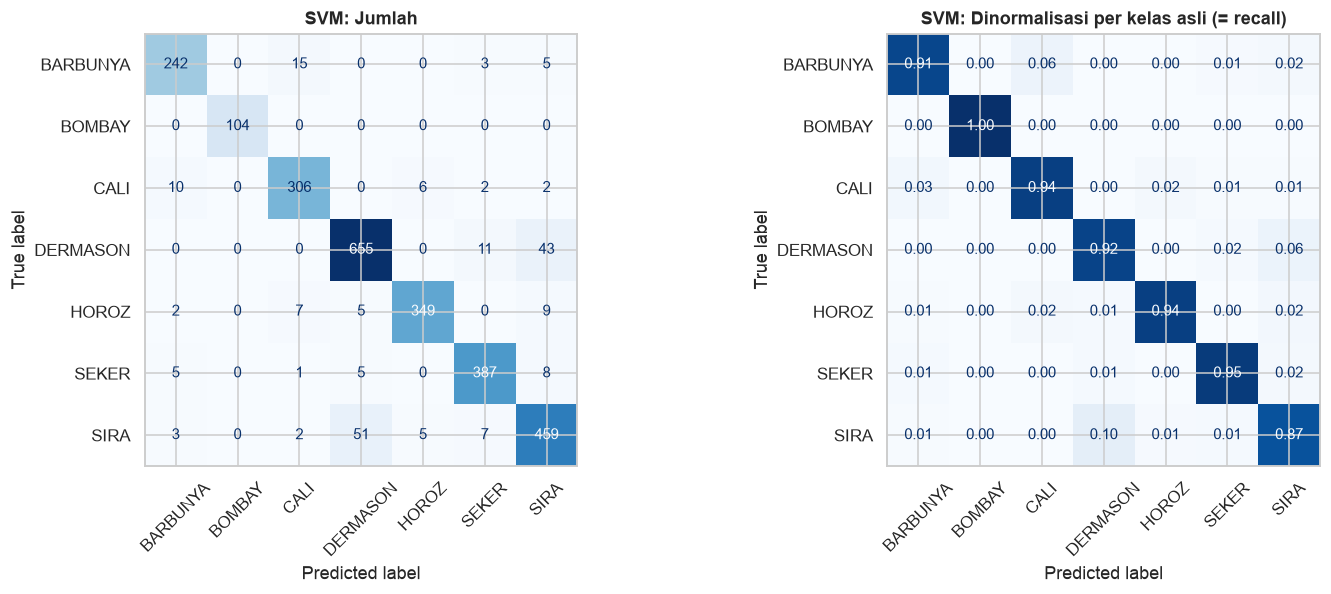

In [22]:
model_svm = gs_svm.best_estimator_
param_svm = {k.replace("classifier__", ""): v for k, v in gs_svm.best_params_.items()}

t0 = time.perf_counter()
model_svm.fit(X_latih, y_latih)
waktu_svm = time.perf_counter() - t0

pred_svm = model_svm.predict(X_uji)
evaluasi_model("SVM", y_uji, pred_svm, waktu_svm, param_svm)
n_sv = model_svm.named_steps["classifier"].n_support_.sum()
print(f"Jumlah support vector : {n_sv:,} dari {len(X_latih):,} sampel latih ({n_sv / len(X_latih) * 100:.1f}%)")
gambar_cm("SVM", y_uji, pred_svm)

kombinasi terbaik adalah kernel RBF dengan `C=10` dan `gamma="scale"`. akurasi uji 0,9236 dan F1 macro 0,9347, lebih tinggi sekitar 2 poin dari Decision Tree. hanya 1.915 dari 10.834 sampel latih (17,7%) yang jadi support vector, artinya model cuma butuh sebagian kecil data untuk menggambar batas keputusan. `BOMBAY` tetap sempurna, `SIRA` masih paling lemah (F1 0,8718) tapi lebih baik dari pohon.

artificial neural network (ANN / MLP)

*multilayer perceptron* dengan fungsi aktivasi ReLU dan optimizer Adam. yang dicari lewat grid: arsitektur (`hidden_layer_sizes`), regularisasi L2 (`alpha`), dan *learning rate*. `early_stopping=True` (10% data latih dipakai sebagai validasi internal) supaya pelatihan berhenti saat tidak membaik lagi. data distandardisasi di dalam `Pipeline`.

In [23]:
pipa_ann = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(activation="relu", solver="adam", max_iter=500,
                                 early_stopping=True, n_iter_no_change=15,
                                 random_state=randomState)),
])
grid_ann = {
    "classifier__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "classifier__alpha": [1e-4, 1e-2],
    "classifier__learning_rate_init": [1e-3, 5e-3],
}

t0 = time.perf_counter()
gs_ann = GridSearchCV(pipa_ann, grid_ann, cv=cv, scoring="f1_macro", n_jobs=-1)
gs_ann.fit(X_latih, y_latih)
waktu_tuning_ann = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktu_tuning_ann:.1f} s ({len(gs_ann.cv_results_['params'])} kombinasi x 5 fold)")
print(f"F1-macro CV terbaik : {gs_ann.best_score_:.4f}")
display(ringkas_tuning(gs_ann))

Grid search selesai dalam 4.6 s (16 kombinasi x 5 fold)
F1-macro CV terbaik : 0.9440


,params,mean_test_score,std_test_score,rank_test_score
0,"{'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.005}",0.9440,0.0044,1
1,"{'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.005}",0.9424,0.0050,2
2,"{'alpha': 0.01, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.005}",0.9416,0.0045,3
3,"{'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}",0.9411,0.0032,4
4,"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.005}",0.9410,0.0049,5
5,"{'alpha': 0.01, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}",0.9400,0.0018,6
6,"{'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.005}",0.9398,0.0064,7
7,"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.005}",0.9386,0.0035,8


Hyperparameter terbaik: {'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.005}
Akurasi              0.9155
Precision (macro)    0.9293
Recall (macro)       0.9265
F1 (macro)           0.9276
F1 (weighted)        0.9153
Waktu latih (s)      0.2138 

              precision    recall  f1-score   support

    BARBUNYA     0.9195    0.9057    0.9125       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9107    0.9387    0.9245       326
    DERMASON     0.8988    0.9267    0.9125       709
       HOROZ     0.9798    0.9140    0.9458       372
       SEKER     0.9240    0.9581    0.9407       406
        SIRA     0.8723    0.8425    0.8571       527

    accuracy                         0.9155      2709
   macro avg     0.9293    0.9265    0.9276      2709
weighted avg     0.9159    0.9155    0.9153      2709



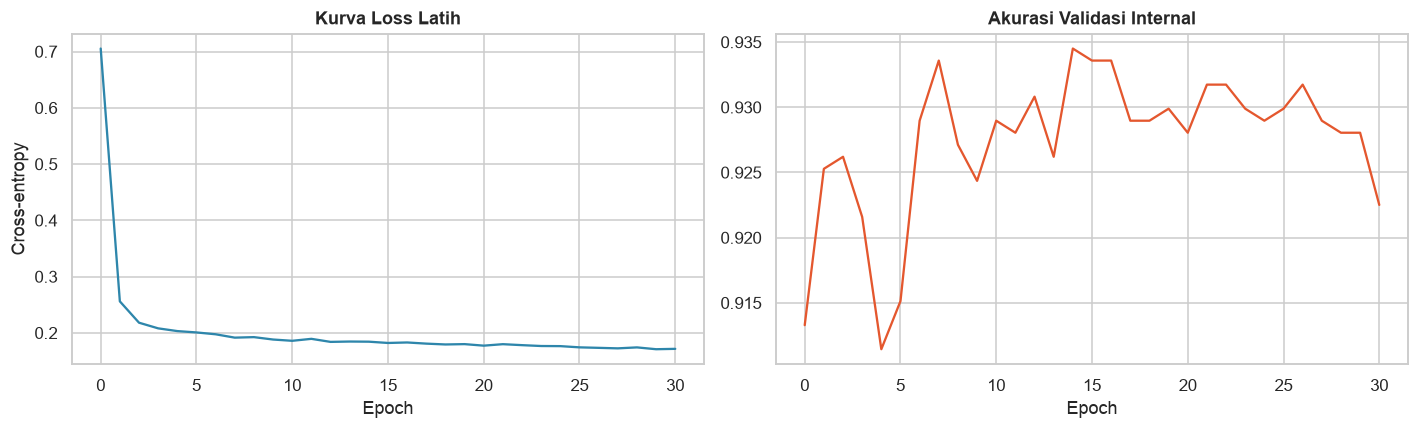

Pelatihan berhenti di epoch ke-31 (early stopping)


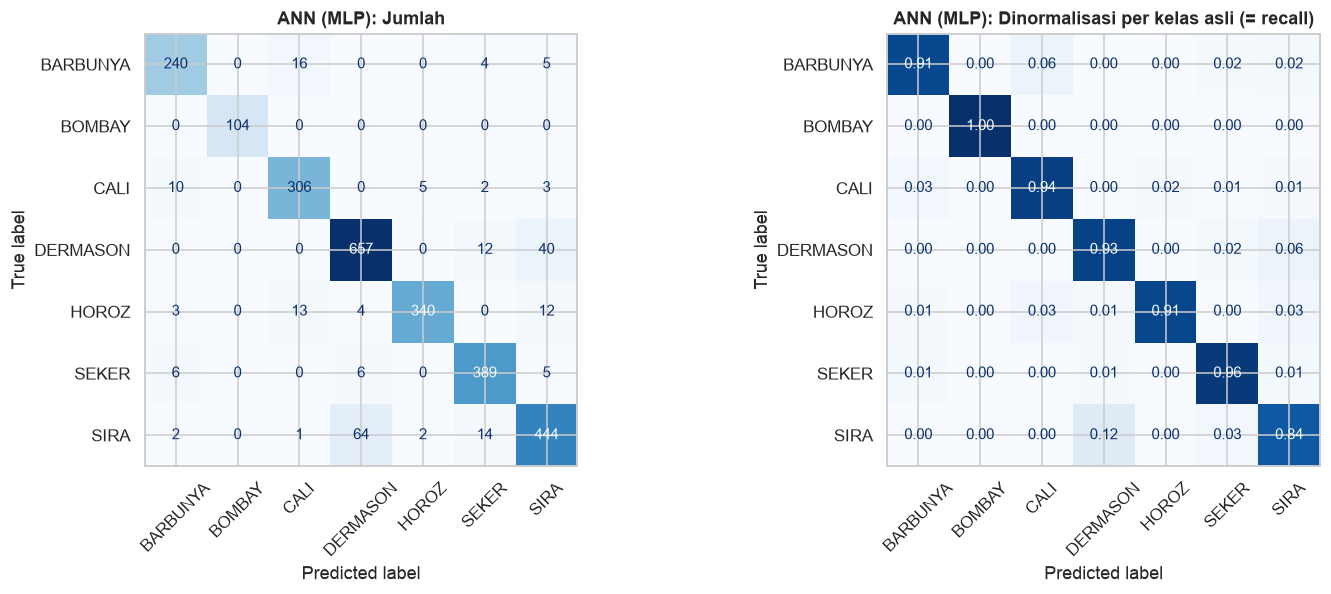

In [24]:
model_ann = gs_ann.best_estimator_
param_ann = {k.replace("classifier__", ""): v for k, v in gs_ann.best_params_.items()}

t0 = time.perf_counter()
model_ann.fit(X_latih, y_latih)
waktu_ann = time.perf_counter() - t0

pred_ann = model_ann.predict(X_uji)
evaluasi_model("ANN (MLP)", y_uji, pred_ann, waktu_ann, param_ann)

mlp = model_ann.named_steps["classifier"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(mlp.loss_curve_, color="#2E86AB")
axes[0].set_title("Kurva Loss Latih")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")

axes[1].plot(mlp.validation_scores_, color="#E4572E")
axes[1].set_title("Akurasi Validasi Internal")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

print(f"Pelatihan berhenti di epoch ke-{mlp.n_iter_} (early stopping)")
gambar_cm("ANN (MLP)", y_uji, pred_ann)

arsitektur terbaik cukup sederhana, satu hidden layer 64 neuron dengan `alpha=1e-4` dan `learning_rate_init=5e-3`. skor CV-nya (F1 macro 0,9440) setara SVM (0,9438), tapi di data uji akurasinya 0,9155 dan F1 macro 0,9276, sedikit di bawah SVM. selisih ini sebenarnya perlu dilihat dengan hati-hati, karena ANN diinisialisasi acak, jadi satu kali latih bisa kebetulan lebih jelek atau lebih bagus. hal ini dicek dengan beberapa seed di bagian perbandingan.

deep learning: CNN 1D (PyTorch)

bagian Deep Learning (CNN atau RNN) di tugas bersifat opsional, di sini dipakai **CNN 1D**. Ke-16 fitur diperlakukan sebagai deret satu kanal dengan panjang 16 (bentuk input `batch x 1 x 16`), lalu konvolusi 1D mencari pola lokal antar fitur yang bertetangga.

perlu dicatat bahwa fitur tabular tidak punya urutan alami, urutan kolomnya arbitrer, padahal CNN mengasumsikan ada struktur lokal (seperti piksel yang bertetangga di gambar). jadi CNN di sini lebih sebagai percobaan pembanding, bukan pilihan yang paling cocok secara teori untuk data ini. ekspektasi yang wajar adalah setara dengan ANN, belum tentu lebih baik.

detail pelatihan:

- optimizer Adam (lr 1e-3, weight decay 1e-4), loss *cross-entropy*, batch 128, maksimal 120 epoch.
- 15% data latih dipisah sebagai validasi untuk *early stopping* (patience 15), bobot terbaik dikembalikan.
- dijalankan di CPU.

In [25]:
class CNN1D(nn.Module):
    def __init__(self, n_fitur: int, n_kelas: int):
        super().__init__()
        self.ekstraksi = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.MaxPool1d(2),
        )
        self.klasifikasi = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (n_fitur // 4), 128), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_kelas),
        )

    def forward(self, x):
        return self.klasifikasi(self.ekstraksi(x))

torch.manual_seed(randomState)
print(CNN1D(len(fitur), len(kelas)))
print("\nJumlah parameter:", sum(p.numel() for p in CNN1D(len(fitur), len(kelas)).parameters()))

CNN1D(
  (ekstraksi): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (klasifikasi): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=7, 

In [26]:
# standardisasi untuk CNN (scaler di-fit pada data latih saja)
scaler_cnn = StandardScaler().fit(X_latih)
X_latih_s = scaler_cnn.transform(X_latih).astype(np.float32)
X_uji_s = scaler_cnn.transform(X_uji).astype(np.float32)

# pisahkan 15% data latih sebagai validasi untuk early stopping
X_a, X_v, y_a, y_v = train_test_split(X_latih_s, y_latih, test_size=0.15,
                                      stratify=y_latih, random_state=randomState)

def buat_loader(X_, y_, acak: bool, seed: int = randomState, batch: int = 128) -> DataLoader:
    ds = TensorDataset(torch.from_numpy(X_).unsqueeze(1), torch.from_numpy(y_).long())
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=torch.Generator().manual_seed(seed))

loader_val = buat_loader(X_v, y_v, acak=False)

fungsi_loss = nn.CrossEntropyLoss()
maksEpoch, sabar = 120, 15

def jalankan_epoch(model, loader, optimizer=None):
    # kalo optimizer dikasih berarti mode latih, kalo nggak mode evaluasi
    latih = optimizer is not None
    model.train(latih)
    total_loss = total_benar = n = 0
    with torch.set_grad_enabled(latih):
        for xb, yb in loader:
            keluaran = model(xb)
            loss = fungsi_loss(keluaran, yb)
            if latih:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            total_benar += (keluaran.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, total_benar / n

def latih_cnn(seed: int, cetak: bool = True):
    # latih satu CNN dengan early stopping, balikin model dengan bobot terbaik
    torch.manual_seed(seed)
    model = CNN1D(len(fitur), len(kelas))
    loader_latih = buat_loader(X_a, y_a, acak=True, seed=seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    riwayat = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    val_terbaik, bobot_terbaik, tunggu, epoch_terbaik = np.inf, None, 0, 0

    t0 = time.perf_counter()
    for epoch in range(1, maksEpoch + 1):
        loss, acc = jalankan_epoch(model, loader_latih, optimizer)
        val_loss, val_acc = jalankan_epoch(model, loader_val)
        for k, v in zip(riwayat, (loss, val_loss, acc, val_acc)):
            riwayat[k].append(v)

        if val_loss < val_terbaik - 1e-4:
            val_terbaik, tunggu, epoch_terbaik = val_loss, 0, epoch
            bobot_terbaik = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            tunggu += 1

        if cetak and (epoch % 10 == 0 or epoch == 1):
            print(f"Epoch {epoch:3d} | loss {loss:.4f} acc {acc:.4f} | val_loss {val_loss:.4f} val_acc {val_acc:.4f}")
        if tunggu >= sabar:
            if cetak:
                print(f"Early stopping di epoch {epoch}")
            break

    waktu = time.perf_counter() - t0
    model.load_state_dict(bobot_terbaik)
    model.eval()
    return model, riwayat, epoch_terbaik, val_terbaik, waktu

def prediksi_cnn(model, X_) -> np.ndarray:
    with torch.no_grad():
        return model(torch.from_numpy(X_).unsqueeze(1)).argmax(1).numpy()

model_cnn, riwayat, epoch_terbaik, val_terbaik, waktu_cnn = latih_cnn(randomState)
print(f"\nBobot terbaik dari epoch {epoch_terbaik} (val_loss = {val_terbaik:.4f}) | waktu latih {waktu_cnn:.1f} s")

Epoch   1 | loss 0.3821 acc 0.8768 | val_loss 0.1694 val_acc 0.9397


Epoch  10 | loss 0.1778 acc 0.9334 | val_loss 0.1715 val_acc 0.9379


Epoch  20 | loss 0.1564 acc 0.9387 | val_loss 0.1659 val_acc 0.9453


Early stopping di epoch 22

Bobot terbaik dari epoch 7 (val_loss = 0.1615) | waktu latih 29.0 s


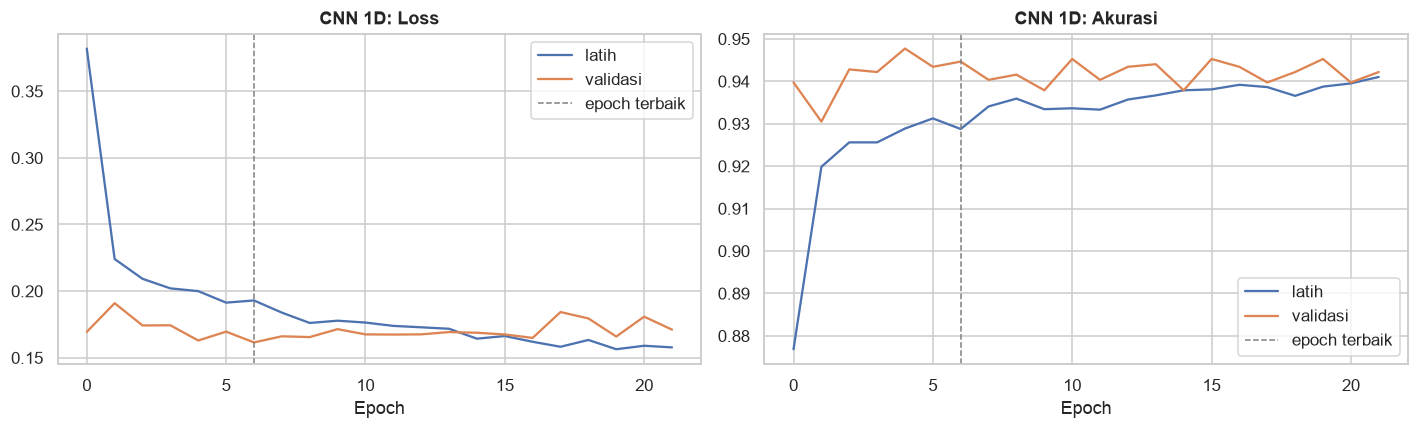

Hyperparameter terbaik: {'epoch_terbaik': 7, 'optimizer': 'Adam lr=1e-3', 'batch': 128}
Akurasi               0.9247
Precision (macro)     0.9373
Recall (macro)        0.9363
F1 (macro)            0.9367
F1 (weighted)         0.9249
Waktu latih (s)      29.0065 

              precision    recall  f1-score   support

    BARBUNYA     0.9280    0.9245    0.9263       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9231    0.9571    0.9398       326
    DERMASON     0.9219    0.9154    0.9186       709
       HOROZ     0.9747    0.9328    0.9533       372
       SEKER     0.9549    0.9384    0.9466       406
        SIRA     0.8585    0.8861    0.8721       527

    accuracy                         0.9247      2709
   macro avg     0.9373    0.9363    0.9367      2709
weighted avg     0.9255    0.9247    0.9249      2709



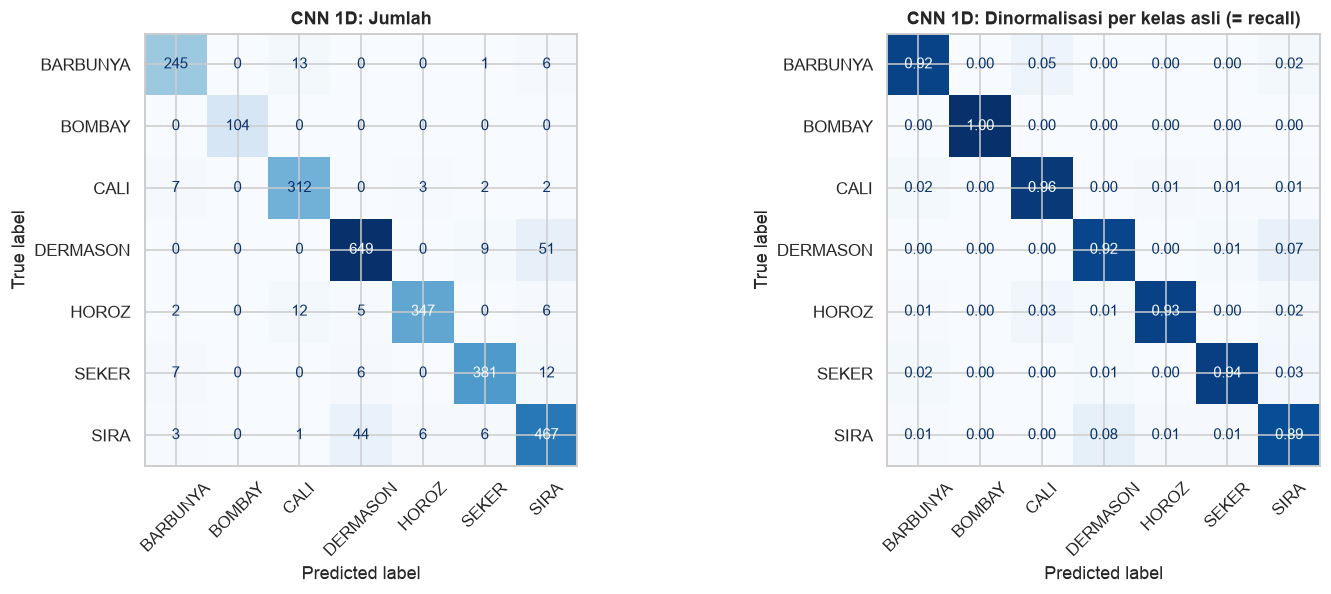

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(riwayat["loss"], label="latih")
axes[0].plot(riwayat["val_loss"], label="validasi")
axes[0].axvline(epoch_terbaik - 1, ls="--", c="gray", lw=1, label="epoch terbaik")
axes[0].set_title("CNN 1D: Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(riwayat["acc"], label="latih")
axes[1].plot(riwayat["val_acc"], label="validasi")
axes[1].axvline(epoch_terbaik - 1, ls="--", c="gray", lw=1, label="epoch terbaik")
axes[1].set_title("CNN 1D: Akurasi")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

pred_cnn = prediksi_cnn(model_cnn, X_uji_s)
evaluasi_model("CNN 1D", y_uji, pred_cnn, waktu_cnn,
               {"epoch_terbaik": epoch_terbaik, "optimizer": "Adam lr=1e-3", "batch": 128})
gambar_cm("CNN 1D", y_uji, pred_cnn)

val loss paling kecil didapat di epoch ke-7, lalu cenderung datar dan fluktuatif sampai *early stopping* menghentikan pelatihan di epoch ke-22. akurasi validasi sedikit lebih tinggi dari akurasi latih karena selama latih ada `Dropout` dan `BatchNorm` yang aktif, sedangkan saat validasi dua-duanya dimatikan.

akurasi uji 0,9247 dan F1 macro 0,9367, nyaris sama dengan SVM (0,9236 dan 0,9347), tapi waktu latihnya puluhan detik, jauh lebih lama dari SVM yang cuma sekitar 0,1 detik (waktu persisnya bervariasi tiap kali dijalankan). apakah selisih kecil ini berarti, dicek di bagian berikutnya.

# Perbandingan hasil

tabel perbandingan (data uji)

In [28]:
tabel_hasil = pd.DataFrame(hasilEvaluasi).T
tabel_hasil.index.name = "Metode"
kolom_metrik = ["Akurasi", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 (weighted)"]
tabel_hasil = tabel_hasil[kolom_metrik + ["Waktu latih (s)"]].sort_values("F1 (macro)", ascending=False)

display(tabel_hasil.style
        .format({**{k: "{:.4f}" for k in kolom_metrik}, "Waktu latih (s)": "{:.2f}"})
        .background_gradient(cmap="Greens", subset=kolom_metrik, axis=0))
print(f"Jumlah data uji : {len(y_uji):,}")

,Akurasi,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Waktu latih (s)
Metode,,,,,,
CNN 1D,0.9247,0.9373,0.9363,0.9367,0.9249,29.01
SVM,0.9236,0.9356,0.9340,0.9347,0.9236,0.14
ANN (MLP),0.9155,0.9293,0.9265,0.9276,0.9153,0.21
Decision Tree,0.9022,0.9141,0.9126,0.9132,0.9021,0.08


Jumlah data uji : 2,709


urutan berdasarkan F1 macro: CNN 1D (0,9367), SVM (0,9347), ANN (0,9276), lalu Decision Tree (0,9132). selisih paling besar ada antara tiga model teratas dan Decision Tree. selisih di antara tiga model teratas kecil sekali, jadi perlu dicek apakah selisih sekecil itu cukup kuat untuk dijadikan dasar menyebut salah satu metode lebih baik.

selang kepercayaan akurasi (bootstrap)

In [29]:
# bootstrap data uji 2000x buat dapat selang kepercayaan 95% akurasi tiap model
rng = np.random.default_rng(randomState)
n_uji, B = len(y_uji), 2000
indeks = rng.integers(0, n_uji, size=(B, n_uji))

batas = {}
for nama, pred in prediksi.items():
    benar = (pred == y_uji).astype(float)
    akurasi_boot = benar[indeks].mean(axis=1)
    batas[nama] = (np.percentile(akurasi_boot, 2.5), np.percentile(akurasi_boot, 97.5))

tabel_ci = pd.DataFrame(batas, index=["batas_bawah", "batas_atas"]).T
tabel_ci.insert(0, "Akurasi", tabel_hasil["Akurasi"])
tabel_ci["lebar"] = tabel_ci["batas_atas"] - tabel_ci["batas_bawah"]
display(tabel_ci.sort_values("Akurasi", ascending=False).round(4))

,Akurasi,batas_bawah,batas_atas,lebar
CNN 1D,0.9247,0.9147,0.9347,0.0199
SVM,0.9236,0.9136,0.9336,0.0199
ANN (MLP),0.9155,0.9051,0.9262,0.0210
Decision Tree,0.9022,0.8915,0.9133,0.0218


selang kepercayaan 95% tiap model lebarnya sekitar 2 poin (±1 poin). selang CNN, SVM, dan ANN saling tumpang tindih besar. selang Decision Tree (0,8915 sampai 0,9133) tidak tumpang tindih dengan selang CNN (0,9147 sampai 0,9347) maupun SVM (0,9136 sampai 0,9336). jadi selisih di bawah 1 poin tidak bisa dijadikan dasar untuk bilang satu metode lebih bagus.

visualisasi perbandingan metrik dan waktu

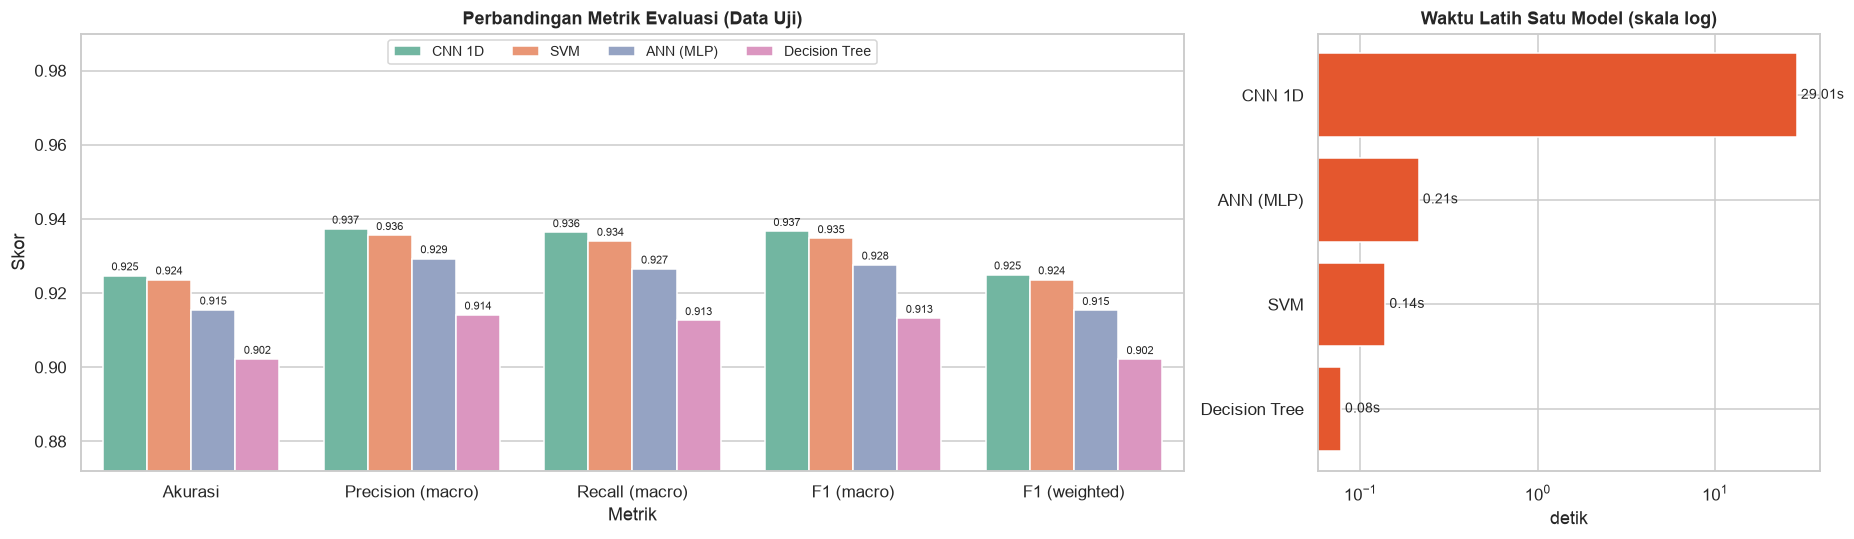

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})

data_plot = tabel_hasil[kolom_metrik].reset_index().melt(id_vars="Metode", var_name="Metrik", value_name="Skor")
sns.barplot(data=data_plot, x="Metrik", y="Skor", hue="Metode", palette="Set2", ax=axes[0])
axes[0].set_ylim(max(0, data_plot["Skor"].min() - 0.03), 0.99)
axes[0].set_title("Perbandingan Metrik Evaluasi (Data Uji)")
axes[0].legend(loc="upper center", ncol=4, fontsize=9)
for wadah in axes[0].containers:
    axes[0].bar_label(wadah, fmt="%.3f", fontsize=7, padding=2)

waktu = tabel_hasil["Waktu latih (s)"].sort_values()
axes[1].barh(waktu.index, waktu.values, color="#E4572E")
axes[1].set_xscale("log")
for i, v in enumerate(waktu.values):
    axes[1].text(v, i, f" {v:.2f}s", va="center", fontsize=9)
axes[1].set_title("Waktu Latih Satu Model (skala log)")
axes[1].set_xlabel("detik")

plt.tight_layout()
plt.show()

pola akurasi, precision, recall, dan F1 sama di semua metrik, jadi urutan model tidak bergantung pada metrik yang dipilih. dari sisi waktu, CNN lebih dari 100x lebih lama dari SVM dan ANN (skala sumbu-x logaritmik, jadi selisihnya tidak terlihat sebesar kenyataannya).

performa per kelas

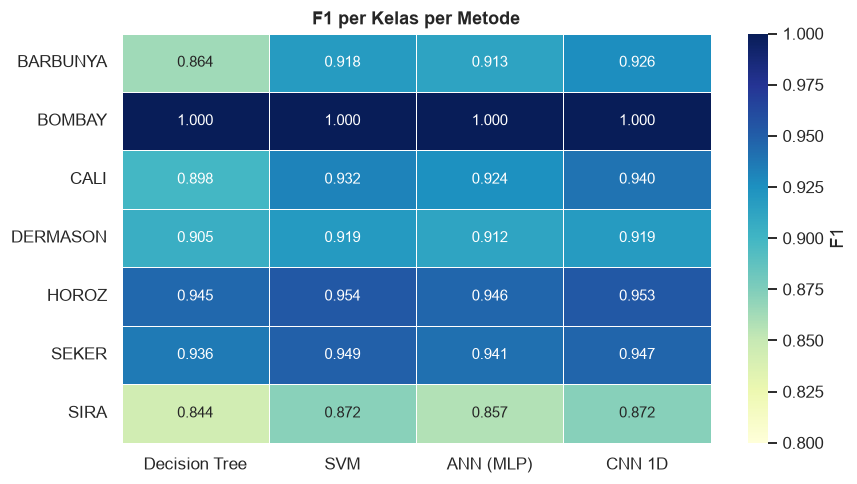

,Decision Tree,SVM,ANN (MLP),CNN 1D,jumlah_uji
BARBUNYA,0.8641,0.9184,0.9125,0.9263,265
BOMBAY,1.0000,1.0000,1.0000,1.0000,104
CALI,0.8985,0.9315,0.9245,0.9398,326
DERMASON,0.9049,0.9193,0.9125,0.9186,709
HOROZ,0.9452,0.9536,0.9458,0.9533,372
SEKER,0.9363,0.9485,0.9407,0.9466,406
SIRA,0.8436,0.8718,0.8571,0.8721,527


In [31]:
f1_per_kelas = pd.DataFrame({nama: f1_score(y_uji, pred, average=None) for nama, pred in prediksi.items()}, index=kelas)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(f1_per_kelas, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.8, vmax=1.0,
            linewidths=.5, cbar_kws={"label": "F1"}, ax=ax)
ax.set_title("F1 per Kelas per Metode")
plt.tight_layout()
plt.show()

f1_per_kelas["jumlah_uji"] = pd.Series(y_uji).value_counts().sort_index().values
display(f1_per_kelas.round(4))

In [32]:
# pasangan kelas yang paling sering tertukar (rata-rata lintas model)
baris = []
for nama, pred in prediksi.items():
    cm = confusion_matrix(y_uji, pred)
    for i in range(len(kelas)):
        for j in range(len(kelas)):
            if i != j and cm[i, j] > 0:
                baris.append((nama, kelas[i], kelas[j], cm[i, j]))

salah = pd.DataFrame(baris, columns=["Model", "Kelas asli", "Diprediksi", "n"])
pasangan_tertukar = salah.groupby(["Kelas asli", "Diprediksi"])["n"].mean().sort_values(ascending=False).head(6)
print("Rata-rata jumlah salah klasifikasi per pasangan kelas (lintas 4 model), 6 teratas:")
print(pasangan_tertukar.round(1).to_string())

Rata-rata jumlah salah klasifikasi per pasangan kelas (lintas 4 model), 6 teratas:
Kelas asli  Diprediksi
SIRA        DERMASON      57.0
DERMASON    SIRA          43.5
BARBUNYA    CALI          15.8
CALI        BARBUNYA      13.0
DERMASON    SEKER         12.2
HOROZ       CALI          11.0


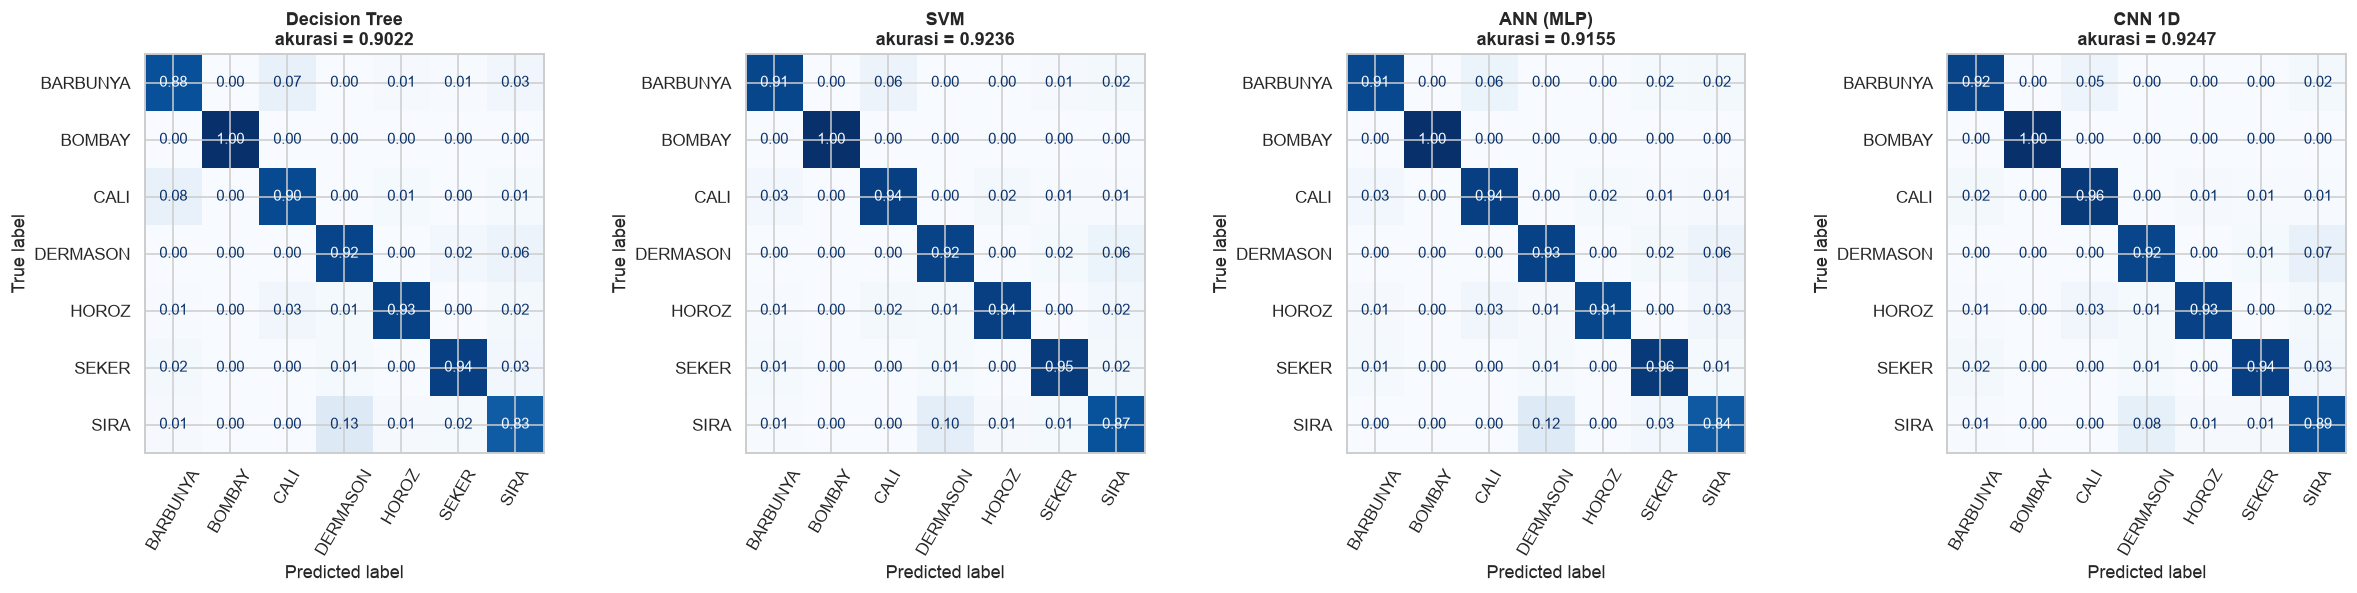

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))
for ax, (nama, pred) in zip(axes, prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(y_uji, pred, display_labels=kelas, normalize="true",
                                            cmap="Blues", values_format=".2f", colorbar=False, ax=ax)
    ax.set_title(f"{nama}\nakurasi = {accuracy_score(y_uji, pred):.4f}")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

- `BOMBAY` sempurna (F1 = 1,00) di keempat model, sesuai dugaan dari EDA bahwa ukurannya jauh beda dari kelas lain.
- `SIRA` kelas tersulit di semua model (F1 antara 0,84 dan 0,87). kesalahan terbesar adalah `SIRA` jadi `DERMASON` (rata-rata sekitar 57 biji per model) dan sebaliknya `DERMASON` jadi `SIRA` (sekitar 44 biji), dari 2.709 data uji. dua varietas ini memang mirip pada ukuran dan bentuk, seperti terlihat di scatter plot EDA.
- pasangan lain yang sering tertukar adalah `BARBUNYA` dengan `CALI` dan `DERMASON` jadi `SEKER`.
- decision tree paling banyak salah di `BARBUNYA` dan `SIRA`, sedangkan tiga model lain lebih rata.

skor CV vs skor uji

In [34]:
cv_terbaik = {"Decision Tree": gs_dt.best_score_, "SVM": gs_svm.best_score_, "ANN (MLP)": gs_ann.best_score_}
konsistensi = pd.DataFrame({
    "F1-macro CV (latih)": pd.Series(cv_terbaik),
    "F1-macro uji":        tabel_hasil["F1 (macro)"].reindex(cv_terbaik.keys()),
})
konsistensi["selisih"] = konsistensi["F1-macro uji"] - konsistensi["F1-macro CV (latih)"]
display(konsistensi.round(4))

,F1-macro CV (latih),F1-macro uji,selisih
Decision Tree,0.9270,0.9132,-0.0137
SVM,0.9438,0.9347,-0.0090
ANN (MLP),0.9440,0.9276,-0.0164


skor di data uji lebih rendah 0,9 sampai 1,6 poin dari skor CV, wajar karena hyperparameter dipilih berdasarkan skor CV itu sendiri. selisihnya kecil dan mirip antar model, jadi tidak ada tanda *overfitting* berat.

uji signifikansi (McNemar) dan kestabilan terhadap seed

dengan 2.709 data uji, selisih akurasi di bawah 1 poin gampang terjadi karena kebetulan. dua pemeriksaan tambahan:

1. **uji McNemar (exact)** membandingkan sampel yang dibenarkan oleh satu model tapi disalahkan model lain, pada data uji yang sama. ini uji berpasangan, jadi lebih tajam dibanding membandingkan selang kepercayaan.
2. **kestabilan terhadap seed** karena ANN dan CNN diinisialisasi acak. keduanya dilatih ulang dengan 5 seed lain (hyperparameter sama), lalu dilihat rata-rata dan simpangan bakunya.

In [35]:
baris = []
for a, b in combinations(prediksi, 2):
    benar_a, benar_b = prediksi[a] == y_uji, prediksi[b] == y_uji
    hanya_a = int((benar_a & ~benar_b).sum())
    hanya_b = int((~benar_a & benar_b).sum())
    p = binomtest(hanya_a, hanya_a + hanya_b, 0.5).pvalue if hanya_a + hanya_b else 1.0
    baris.append((a, b, hanya_a, hanya_b, p, "ya" if p < 0.05 else "tidak"))

tabel_mcnemar = pd.DataFrame(baris, columns=["Model A", "Model B", "A benar & B salah", "B benar & A salah",
                                             "p-value", "Beda signifikan (alpha=0.05)?"])
display(tabel_mcnemar.round(4))

,Model A,Model B,A benar & B salah,B benar & A salah,p-value,Beda signifikan (alpha=0.05)?
0,Decision Tree,SVM,43,101,0.0000,ya
1,Decision Tree,ANN (MLP),59,95,0.0046,ya
2,Decision Tree,CNN 1D,50,111,0.0000,ya
3,SVM,ANN (MLP),41,19,0.0062,ya
4,SVM,CNN 1D,27,30,0.7914,tidak
5,ANN (MLP),CNN 1D,34,59,0.0124,ya


In [36]:
seedUlang = [1, 2, 3, 4, 5]
hasil_seed = {"ANN (MLP)": [], "CNN 1D": []}

for sd in seedUlang:
    # ANN: hyperparameter sama, cuma random_state yang diganti
    ann_ulang = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(activation="relu", solver="adam", max_iter=500, early_stopping=True,
                                     n_iter_no_change=15, random_state=sd, **param_ann)),
    ]).fit(X_latih, y_latih)
    pred = ann_ulang.predict(X_uji)
    hasil_seed["ANN (MLP)"].append((accuracy_score(y_uji, pred), f1_score(y_uji, pred, average="macro")))

    # CNN: latih ulang dengan seed berbeda
    cnn_ulang, *_ = latih_cnn(sd, cetak=False)
    pred = prediksi_cnn(cnn_ulang, X_uji_s)
    hasil_seed["CNN 1D"].append((accuracy_score(y_uji, pred), f1_score(y_uji, pred, average="macro")))

ringkas_seed = pd.DataFrame({
    nama: {
        "Akurasi rata-rata":  np.mean([a for a, _ in v]),
        "Akurasi std":        np.std([a for a, _ in v], ddof=1),
        "Akurasi min":        min(a for a, _ in v),
        "Akurasi maks":       max(a for a, _ in v),
        "F1 macro rata-rata": np.mean([f for _, f in v]),
        "F1 macro std":       np.std([f for _, f in v], ddof=1),
    } for nama, v in hasil_seed.items()
}).T

print(f"Hasil 5 seed berbeda {seedUlang} pada data uji yang sama (DT dan SVM deterministik, tidak perlu diulang):")
display(ringkas_seed.round(4))

Hasil 5 seed berbeda [1, 2, 3, 4, 5] pada data uji yang sama (DT dan SVM deterministik, tidak perlu diulang):


,Akurasi rata-rata,Akurasi std,Akurasi min,Akurasi maks,F1 macro rata-rata,F1 macro std
ANN (MLP),0.9241,0.0021,0.9217,0.9269,0.9349,0.0022
CNN 1D,0.9230,0.0021,0.9203,0.9254,0.9344,0.0020


hasil McNemar:

| perbandingan | p-value | signifikan? |
|---|---|---|
| decision tree vs SVM | < 0,0001 | ya |
| decision tree vs CNN | < 0,0001 | ya |
| decision tree vs ANN | 0,0046 | ya |
| SVM vs CNN | 0,7914 | tidak |
| SVM vs ANN | 0,0062 | ya |
| ANN vs CNN | 0,0124 | ya |

decision tree memang lebih rendah dari ketiga model lain secara signifikan. SVM vs CNN tidak signifikan, artinya tidak ada bukti keduanya berbeda.

tapi hasil ANN lebih rendah dari SVM dan CNN pada tabel di atas perlu dibaca bersama hasil uji seed. setelah dilatih ulang dengan 5 seed, ANN rata-rata akurasinya 0,9241 (std 0,0021) dan CNN 0,9230 (std 0,0021), setara SVM (0,9236). jadi seed 42 untuk ANN kebetulan agak jelek (0,9155, di bawah semua 5 seed lain yang minimal 0,9217). uji McNemar cuma menilai satu instans model, bukan kemampuan metodenya secara umum. sebaliknya CNN seed 42 (0,9247) masih dalam kisaran seed lain (0,9203 sampai 0,9254), jadi bukan bukti CNN lebih unggul.

# Eksperimen perbaikan model

hasil di atas memunculkan pertanyaan, apakah ada yang bisa dilakukan supaya tiap metode lebih baik? untuk menjawabnya, beberapa perubahan dicoba untuk keempat metode. aturan mainnya:

- metode tidak boleh ganti jenis. pohon tetap satu pohon (bukan Random Forest atau boosting), SVM tetap SVM, ANN tetap MLP, CNN tetap CNN 1D.
- hyperparameter varian Decision Tree, SVM, dan ANN dicari lewat `GridSearchCV` (5-fold, skor F1 macro) **di data latih saja**, sama seperti model dasar. data uji hanya dipakai untuk melaporkan hasil, bukan untuk memilih konfigurasi. resep CNN dijelaskan terpisah di bagiannya.
- metode neural dilaporkan dengan 5 seed, karena satu kali latih saja sudah bisa berbeda sekitar 1 poin akibat inisialisasi acak.

yang dicoba di sini: fitur rasio untuk Decision Tree, `PowerTransformer` untuk SVM, ANN tanpa *early stopping*, dan resep latih alternatif untuk CNN (fitur log, AdamW + OneCycle, *label smoothing*, pelatihan di seluruh data latih). ide-idenya datang dari temuan EDA: fitur ukuran miring kanan dan `Solidity` serta `ShapeFactor4` miring kiri (cocok untuk log atau Yeo-Johnson), serta fitur ukuran yang saling berkorelasi sangat kuat (cocok untuk rasio antar fitur).

decision tree dengan fitur rasio

pohon keputusan hanya bisa membelah dengan satu fitur per split (batasnya sejajar sumbu), jadi ia tidak bisa membentuk rasio antar kolom sendiri. sepuluh fitur rasio ditambahkan dari 16 fitur asli, misalnya `Perimeter / MajorAxisLength` dan `Area / Perimeter^2`. rasio dihitung baris per baris dari fitur asli (tidak belajar apa pun dari data), jadi aman dari kebocoran.

model dasar tadi dicari tanpa pemangkasan, jadi supaya adil dua varian dicari dengan grid yang sama ditambah `ccp_alpha` (pemangkasan *cost-complexity*): pohon pada 16 fitur asli, dan pohon pada 26 fitur (16 asli + 10 rasio).

In [37]:
namaRasio = ["P/Major", "Minor/P", "A/(Major*Minor)", "log(A)", "log(1-Solidity)",
              "A/P^2", "EquivD/Major", "EquivD/Minor", "Convex/P^2", "A/Major^2"]
fiturRasio = fitur + namaRasio

# tambahin 10 fitur rasio di sebelah kanan 16 fitur asli (kolom asli tetap)
def tambah_rasio(X):
    X = np.asarray(X, dtype=np.float64)
    k = lambda nama: X[:, fitur.index(nama)]
    rasio = [
        k("Perimeter") / k("MajorAxisLength"),
        k("MinorAxisLength") / k("Perimeter"),
        k("Area") / (k("MajorAxisLength") * k("MinorAxisLength")),
        np.log(k("Area")),
        np.log(1 - k("Solidity") + 1e-3),
        k("Area") / k("Perimeter") ** 2,
        k("EquivDiameter") / k("MajorAxisLength"),
        k("EquivDiameter") / k("MinorAxisLength"),
        k("ConvexArea") / k("Perimeter") ** 2,
        k("Area") / k("MajorAxisLength") ** 2,
    ]
    return np.column_stack([X] + rasio)

grid_dt_ccp = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 14, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "ccp_alpha": [0, 2e-4, 5e-4, 1e-3],
}

# varian 1: 16 fitur asli + ccp_alpha
gs_dt_ccp = GridSearchCV(DecisionTreeClassifier(random_state=randomState), grid_dt_ccp,
                         cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_latih, y_latih)

# varian 2: 26 fitur (asli + rasio) + ccp_alpha
pipa_dt_rasio = Pipeline([("rasio", FunctionTransformer(tambah_rasio)),
                          ("pohon", DecisionTreeClassifier(random_state=randomState))])
grid_dt_rasio = {f"pohon__{k}": v for k, v in grid_dt_ccp.items()}
gs_dt_rasio = GridSearchCV(pipa_dt_rasio, grid_dt_rasio, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_latih, y_latih)

print(f"Fitur: {len(fitur)} asli + {len(namaRasio)} rasio = {len(fiturRasio)} kolom | {len(gs_dt_ccp.cv_results_['params'])} kombinasi x 5 fold per varian\n")
tabel_cv_dt = pd.DataFrame({
    "F1-macro CV terbaik": {"DT dasar (tanpa ccp)": gs_dt.best_score_, "DT 16 fitur + ccp": gs_dt_ccp.best_score_,
                            "DT 26 fitur (rasio) + ccp": gs_dt_rasio.best_score_},
    "hyperparameter terbaik": {"DT dasar (tanpa ccp)": str(gs_dt.best_params_), "DT 16 fitur + ccp": str(gs_dt_ccp.best_params_),
                               "DT 26 fitur (rasio) + ccp": str(gs_dt_rasio.best_params_).replace("pohon__", "")},
})
display(tabel_cv_dt.style.format({"F1-macro CV terbaik": "{:.4f}"}))

Fitur: 16 asli + 10 rasio = 26 kolom | 240 kombinasi x 5 fold per varian



,F1-macro CV terbaik,hyperparameter terbaik
DT dasar (tanpa ccp),0.9270,"{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}"
DT 16 fitur + ccp,0.9270,"{'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}"
DT 26 fitur (rasio) + ccp,0.9280,"{'ccp_alpha': 0.0002, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10}"


hasil pencarian di data latih:

- pohon 16 fitur + `ccp_alpha` memilih `ccp_alpha = 0`, artinya pemangkasan tidak membantu. hasilnya sama persis dengan model dasar (F1 macro CV 0,9270).
- pohon 26 fitur (dengan rasio) memilih `ccp_alpha = 2e-4`, dengan hyperparameter lain tetap `entropy`, `max_depth=10`, `min_samples_leaf=10`. F1 macro CV-nya 0,9280, naik 0,0010 dari 0,9270.

jadi pemangkasan sendiri tidak membantu, dan kalau ada perbaikan, sumbernya adalah fitur rasio. selisih 0,001 itu kecil, jadi dicek lagi dengan CV yang diulang di bawah.

In [38]:
model_dt_ccp = gs_dt_ccp.best_estimator_
model_dt_rasio = gs_dt_rasio.best_estimator_
varian_dt = {"DT dasar": model_dt, "DT 16 fitur + ccp": model_dt_ccp, "DT 26 fitur (rasio) + ccp": model_dt_rasio}

# cv 5-fold diulang 5 kali (25 lipatan) di data latih, lipatan sama untuk semua varian supaya bisa dibandingkan berpasangan
cv_ulang = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=randomState)
skor_cv = {nama: cross_val_score(clone(m), X_latih, y_latih, cv=cv_ulang, scoring="f1_macro", n_jobs=-1)
           for nama, m in varian_dt.items()}

baris = []
for nama, skor in skor_cv.items():
    selisih = skor - skor_cv["DT dasar"]
    baris.append({
        "Varian": nama,
        "F1-macro CV (rata-rata 25 lipatan)": skor.mean(),
        "selisih vs dasar": selisih.mean(),
        "SE selisih": selisih.std(ddof=1) / np.sqrt(len(selisih)),
        "lipatan lebih baik dari dasar": f"{int((selisih > 0).sum())} dari {len(selisih)}" if nama != "DT dasar" else "-",
    })
display(pd.DataFrame(baris).set_index("Varian").round(4))

,F1-macro CV (rata-rata 25 lipatan),selisih vs dasar,SE selisih,lipatan lebih baik dari dasar
Varian,,,,
DT dasar,0.9234,0.0000,0.0000,-
DT 16 fitur + ccp,0.9234,0.0000,0.0000,0 dari 25
DT 26 fitur (rasio) + ccp,0.9246,0.0011,0.0008,16 dari 25


pohon 16 fitur + `ccp_alpha` identik dengan model dasar di semua 25 lipatan, karena grid memilih `ccp_alpha = 0`. pohon dengan fitur rasio naik sekitar 0,0011 F1 macro dengan standard error 0,0008, dan lebih baik di 16 dari 25 lipatan. kenaikan itu hanya sekitar 1,4 kali SE-nya, jadi di data latih sinyalnya lemah.

berikutnya, konfigurasi dibekukan lalu dites sekali di data uji.

In [39]:
prediksi_dt_varian = {nama: m.predict(X_uji) for nama, m in varian_dt.items()}

tabel_dt = pd.DataFrame({
    nama: {"Akurasi": accuracy_score(y_uji, p), "Precision (macro)": precision_score(y_uji, p, average="macro"),
           "Recall (macro)": recall_score(y_uji, p, average="macro"), "F1 (macro)": f1_score(y_uji, p, average="macro")}
    for nama, p in prediksi_dt_varian.items()
}).T
display(tabel_dt.round(4))

pohon_rasio = model_dt_rasio.named_steps["pohon"]
print(f"Jumlah daun : DT dasar {model_dt.get_n_leaves()} | DT 16 fitur + ccp {model_dt_ccp.get_n_leaves()} | "
      f"DT 26 fitur + ccp {pohon_rasio.get_n_leaves()} (kedalaman {pohon_rasio.get_depth()})")

# selisih akurasi berpasangan (bootstrap 2000x) dan uji McNemar, dasar vs masing-masing varian
rng = np.random.default_rng(randomState)
idx = rng.integers(0, len(y_uji), size=(2000, len(y_uji)))
benar_dasar = (prediksi_dt_varian["DT dasar"] == y_uji).astype(float)
for nama in ["DT 16 fitur + ccp", "DT 26 fitur (rasio) + ccp"]:
    benar_v = (prediksi_dt_varian[nama] == y_uji).astype(float)
    boot = (benar_v[idx] - benar_dasar[idx]).mean(axis=1)
    hanya_dasar = int(((benar_dasar == 1) & (benar_v == 0)).sum())
    hanya_v = int(((benar_dasar == 0) & (benar_v == 1)).sum())
    print(f"\n{nama} vs DT dasar")
    print(f"  Selisih akurasi : {(benar_v - benar_dasar).mean():+.4f} | CI 95% bootstrap [{np.percentile(boot, 2.5):+.4f}, {np.percentile(boot, 97.5):+.4f}]")
    if hanya_dasar + hanya_v == 0:
        print("  McNemar         : prediksi identik dengan DT dasar di semua data uji, tidak ada yang diuji")
    else:
        print(f"  McNemar         : hanya dasar benar = {hanya_dasar}, hanya varian benar = {hanya_v}, "
              f"p-value = {binomtest(hanya_dasar, hanya_dasar + hanya_v, 0.5).pvalue:.4f}")

,Akurasi,Precision (macro),Recall (macro),F1 (macro)
DT dasar,0.9022,0.9141,0.9126,0.9132
DT 16 fitur + ccp,0.9022,0.9141,0.9126,0.9132
DT 26 fitur (rasio) + ccp,0.9121,0.9248,0.9235,0.9241


Jumlah daun : DT dasar 197 | DT 16 fitur + ccp 197 | DT 26 fitur + ccp 184 (kedalaman 10)

DT 16 fitur + ccp vs DT dasar
  Selisih akurasi : +0.0000 | CI 95% bootstrap [+0.0000, +0.0000]
  McNemar         : prediksi identik dengan DT dasar di semua data uji, tidak ada yang diuji

DT 26 fitur (rasio) + ccp vs DT dasar
  Selisih akurasi : +0.0100 | CI 95% bootstrap [+0.0030, +0.0173]
  McNemar         : hanya dasar benar = 38, hanya varian benar = 65, p-value = 0.0101


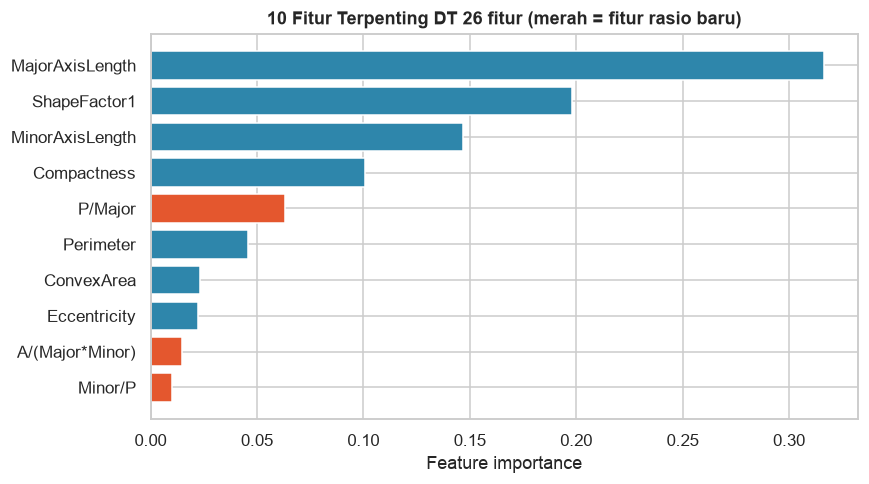

In [40]:
pentingnya_rasio = pd.Series(pohon_rasio.feature_importances_, index=fiturRasio).sort_values(ascending=False).head(10)[::-1]
warna = ["#E4572E" if nama in namaRasio else "#2E86AB" for nama in pentingnya_rasio.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pentingnya_rasio.index, pentingnya_rasio.values, color=warna)
ax.set_title("10 Fitur Terpenting DT 26 fitur (merah = fitur rasio baru)")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

di data uji, pohon 26 fitur + `ccp_alpha` mencapai akurasi 0,9121 dan F1 macro 0,9241, naik sekitar 1 poin dari DT dasar (0,9022 dan 0,9132). selisih akurasinya +0,0100 dengan selang kepercayaan 95% [+0,0030, +0,0173], dan McNemar p = 0,0101, jadi pada data uji selisihnya signifikan. pohonnya juga sedikit lebih kecil (184 daun dari 197). fitur rasio `P/Major` masuk 5 besar, sisanya tetap didominasi fitur asli. pohon 16 fitur + `ccp_alpha` sama persis dengan DT dasar, jadi prediksinya identik.

tapi ada dua hal yang membuat kesimpulannya harus hati-hati:

- di data latih kenaikannya cuma sekitar 0,1 poin F1 (lemah), jauh di bawah +1 poin di data uji. kedua perkiraan ini tidak sejalan, dan data uji cuma satu kali pengambilan sampel. kenaikan yang sebenarnya kemungkinan positif tapi lebih kecil dari 1 poin.
- walaupun begitu, pohon dengan rasio (0,9121) masih di bawah SVM, ANN, dan CNN (sekitar 0,923 sampai 0,924), jadi urutan antar metode tidak berubah.

kesimpulannya fitur rasio **layak dicatat sebagai perbaikan kecil untuk Decision Tree**, bukan perbaikan yang sudah terbukti kuat.

SVM dan ANN: konfigurasi alternatif

dua perubahan lain dicari dengan cara yang sama (`GridSearchCV`, 5-fold, F1 macro, data latih saja):

- **SVM** dengan pilihan scaler `StandardScaler` atau `PowerTransformer` (Yeo-Johnson, untuk fitur yang miring), `C` yang lebih rapat di rentang 10 sampai 100, dan `gamma` yang lebih halus dari model dasar.
- **ANN** tanpa *early stopping* dengan jumlah epoch tetap (150 epoch, `batch_size=64`, `learning_rate_init=1e-3`), mencari arsitektur dan `alpha`.

In [41]:
pipa_svm_alt = Pipeline([("scaler", StandardScaler()), ("classifier", SVC(random_state=randomState))])
grid_svm_alt = {
    "scaler": [StandardScaler(), PowerTransformer()],
    "classifier__C": [10, 30, 100],
    "classifier__gamma": ["scale", 0.01, 0.02, 0.05],
}
gs_svm_alt = GridSearchCV(pipa_svm_alt, grid_svm_alt, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_latih, y_latih)

pipa_ann_alt = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(activation="relu", solver="adam", batch_size=64, learning_rate_init=1e-3,
                                 early_stopping=False, max_iter=150, random_state=randomState)),
])
grid_ann_alt = {
    "classifier__hidden_layer_sizes": [(64,), (128,), (128, 64)],
    "classifier__alpha": [1e-4, 1e-2],
}
gs_ann_alt = GridSearchCV(pipa_ann_alt, grid_ann_alt, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_latih, y_latih)

print("SVM alternatif  : F1-macro CV terbaik", round(gs_svm_alt.best_score_, 4), "| dasar", round(gs_svm.best_score_, 4))
print("  terbaik       :", {k.replace("classifier__", ""): (type(v).__name__ if k == "scaler" else v) for k, v in gs_svm_alt.best_params_.items()})
print("ANN alternatif  : F1-macro CV terbaik", round(gs_ann_alt.best_score_, 4), "| dasar", round(gs_ann.best_score_, 4))
print("  terbaik       :", {k.replace("classifier__", ""): v for k, v in gs_ann_alt.best_params_.items()})
print("\n5 konfigurasi SVM terbaik di CV:")
display(ringkas_tuning(gs_svm_alt, teratas=5))

SVM alternatif  : F1-macro CV terbaik 0.9451 | dasar 0.9438
  terbaik       : {'C': 100, 'gamma': 0.02, 'scaler': 'PowerTransformer'}
ANN alternatif  : F1-macro CV terbaik 0.9458 | dasar 0.944
  terbaik       : {'alpha': 0.0001, 'hidden_layer_sizes': (64,)}

5 konfigurasi SVM terbaik di CV:


,params,mean_test_score,std_test_score,rank_test_score
0,"{'C': 100, 'gamma': 0.02, 'scaler': PowerTransformer()}",0.9451,0.0045,1
1,"{'C': 30, 'gamma': 'scale', 'scaler': PowerTransformer()}",0.9449,0.0036,2
2,"{'C': 30, 'gamma': 0.05, 'scaler': PowerTransformer()}",0.9447,0.0036,3
3,"{'C': 10, 'gamma': 'scale', 'scaler': PowerTransformer()}",0.9447,0.0041,4
4,"{'C': 10, 'gamma': 0.05, 'scaler': PowerTransformer()}",0.9446,0.0045,5


hasil pencarian di data latih:

- **SVM** memilih `PowerTransformer` dengan `C=100` dan `gamma=0.02`, F1 macro CV 0,9451 vs 0,9438 pada model dasar (selisih 0,0013). lima konfigurasi teratas semuanya memakai `PowerTransformer` dan berselisih paling banyak 0,0005 satu sama lain (0,9446 sampai 0,9451), sedangkan simpangan baku antar lipatan sekitar 0,004. jadi kenaikan ini lebih kecil dari noise antar lipatan.
- **ANN tanpa *early stopping*** memilih satu hidden layer 64 neuron dan `alpha=1e-4`, F1 macro CV 0,9458 vs 0,9440 pada model dasar (selisih 0,0018).

In [42]:
# SVM: satu kali latih (deterministik)
pred_svm_alt = gs_svm_alt.best_estimator_.predict(X_uji)

# ANN: 5 seed dengan hyperparameter terbaik hasil pencarian
akurasi_alt, f1_alt = [], []
for sd in seedUlang:
    model_alt = clone(gs_ann_alt.best_estimator_).set_params(classifier__random_state=sd).fit(X_latih, y_latih)
    pred = model_alt.predict(X_uji)
    akurasi_alt.append(accuracy_score(y_uji, pred)); f1_alt.append(f1_score(y_uji, pred, average="macro"))

akurasi_dasar = [a for a, _ in hasil_seed["ANN (MLP)"]]
f1_dasar = [f for _, f in hasil_seed["ANN (MLP)"]]

tabel_alt = pd.DataFrame([
    {"Varian": "SVM dasar", "F1-macro CV (latih)": gs_svm.best_score_, "Akurasi uji": hasilEvaluasi["SVM"]["Akurasi"],
     "F1 macro uji": hasilEvaluasi["SVM"]["F1 (macro)"], "keterangan": "satu kali latih (deterministik)"},
    {"Varian": "SVM alternatif", "F1-macro CV (latih)": gs_svm_alt.best_score_, "Akurasi uji": accuracy_score(y_uji, pred_svm_alt),
     "F1 macro uji": f1_score(y_uji, pred_svm_alt, average="macro"), "keterangan": "satu kali latih (deterministik)"},
    {"Varian": "ANN dasar", "F1-macro CV (latih)": gs_ann.best_score_, "Akurasi uji": np.mean(akurasi_dasar),
     "F1 macro uji": np.mean(f1_dasar), "keterangan": f"rata-rata 5 seed (std akurasi {np.std(akurasi_dasar, ddof=1):.4f})"},
    {"Varian": "ANN alternatif (tanpa early stopping)", "F1-macro CV (latih)": gs_ann_alt.best_score_, "Akurasi uji": np.mean(akurasi_alt),
     "F1 macro uji": np.mean(f1_alt), "keterangan": f"rata-rata 5 seed (std akurasi {np.std(akurasi_alt, ddof=1):.4f})"},
]).set_index("Varian")
display(tabel_alt.round(4))

,F1-macro CV (latih),Akurasi uji,F1 macro uji,keterangan
Varian,,,,
SVM dasar,0.9438,0.9236,0.9347,satu kali latih (deterministik)
SVM alternatif,0.9451,0.9232,0.9341,satu kali latih (deterministik)
ANN dasar,0.9440,0.9241,0.9349,rata-rata 5 seed (std akurasi 0.0021)
ANN alternatif (tanpa early stopping),0.9458,0.9241,0.9344,rata-rata 5 seed (std akurasi 0.0021)


skor CV naik sedikit untuk kedua model, tapi di data uji tidak ada perbaikan. akurasi SVM malah turun tipis (0,9236 menjadi 0,9232). ANN rata-rata 5 seed sama persis di 0,9241 (F1 macro 0,9349 menjadi 0,9344), dengan simpangan baku yang sama (0,0021).

ini wajar. kenaikan skor CV sebesar 0,001 sampai 0,002 lebih kecil dari noise antar lipatan, jadi tidak ada jaminan kenaikan itu berlanjut ke data uji. jadi **tidak ada alasan mengganti konfigurasi SVM maupun ANN**.

CNN 1D

untuk CNN dicoba resep latih alternatif: fitur log (log pada fitur ukuran yang miring kanan, `log(1 - x)` pada fitur yang numpuk di dekat 1), AdamW + OneCycle + *label smoothing*, dan pelatihan 30 epoch tetap pada seluruh data latih tanpa *early stopping*. salah satu hal yang perlu dipisahkan adalah apakah kenaikannya cuma karena 15% data yang biasanya dipakai sebagai validasi ikut dipakai untuk latih.

resep ini dijalankan dengan 5 seed yang sama (1 sampai 5), lalu komponennya dipisah satu per satu. nilai di dalam resep (puncak learning rate 3e-3, weight decay 1e-2, *label smoothing* 0,05, 30 epoch) adalah nilai konvensional yang ditetapkan lebih dulu dan tidak dicari di notebook ini; yang dibandingkan hanya komponennya:

| varian | fitur | optimizer dan loss | data latih dan lama latih |
|---|---|---|---|
| dasar (cek ulang) | standardisasi saja | Adam, cross-entropy biasa | 85% data latih, *early stopping* |
| + fitur log | log pada fitur miring, lalu standardisasi | Adam, cross-entropy biasa | 85%, *early stopping* |
| 30 epoch tetap | standardisasi saja | Adam, cross-entropy biasa | 100% data latih, 30 epoch tanpa *early stopping* |
| + AdamW, OneCycle, *label smoothing* | standardisasi saja | AdamW (wd 1e-2), OneCycle (puncak 3e-3), *label smoothing* 0,05 | 100%, 30 epoch |
| resep percobaan penuh | log, lalu standardisasi | AdamW, OneCycle, *label smoothing* | 100%, 30 epoch |

varian "Dasar" dijalankan lagi lewat fungsi baru sebagai pemeriksaan, hasilnya harus sama dengan 5 seed yang sudah dihitung di bagian sebelumnya. seluruh varian dijalankan paralel (satu thread per proses supaya hasilnya tetap bisa diulang).

In [43]:
from joblib import Parallel, delayed

logFitur = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "ConvexArea", "EquivDiameter",
             "ShapeFactor1", "ShapeFactor2"]
jenuhFitur = ["Solidity", "ShapeFactor4"]
epochTetap = 30

# log buat fitur ukuran (miring kanan), log(1 - x) buat fitur yang numpuk di dekat 1 (miring kiri)
def fitur_log(X):
    X = np.asarray(X, dtype=np.float64).copy()
    for nama in logFitur:
        X[:, fitur.index(nama)] = np.log(X[:, fitur.index(nama)])
    for nama in jenuhFitur:
        X[:, fitur.index(nama)] = np.log(1.0 - X[:, fitur.index(nama)])
    return X

def latih_cnn_varian(seed, pakai_log, resep, penuh):
    # fungsi ini jalan di proses terpisah, jadi thread dan determinisme diset ulang di sini
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    t0 = time.perf_counter()

    X_tr, X_te = (fitur_log(X_latih), fitur_log(X_uji)) if pakai_log else (X_latih, X_uji)
    sc = StandardScaler().fit(X_tr)
    X_tr, X_te = sc.transform(X_tr).astype(np.float32), sc.transform(X_te).astype(np.float32)

    if penuh:
        X_fit, y_fit = X_tr, y_latih
    else:
        X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_latih, test_size=0.15, stratify=y_latih, random_state=randomState)

    def buat_dl(X_, y_, acak):
        ds = TensorDataset(torch.from_numpy(X_).unsqueeze(1), torch.from_numpy(y_).long())
        return DataLoader(ds, batch_size=128, shuffle=acak, generator=torch.Generator().manual_seed(seed))

    torch.manual_seed(seed)
    model = CNN1D(len(fitur), len(kelas))
    dl_latih = buat_dl(X_fit, y_fit, True)

    if resep == "onecycle_ls":
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        jadwal = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=epochTetap * len(dl_latih))
        loss_latih = nn.CrossEntropyLoss(label_smoothing=0.05)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        jadwal = None
        loss_latih = nn.CrossEntropyLoss()
    loss_biasa = nn.CrossEntropyLoss()

    def satu_epoch():
        model.train()
        for xb, yb in dl_latih:
            loss = loss_latih(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            if jadwal is not None:
                jadwal.step()

    if penuh:
        # epoch tetap, tanpa validasi, pakai bobot epoch terakhir
        for _ in range(epochTetap):
            satu_epoch()
    else:
        # early stopping seperti resep dasar: pantau val loss, patience 15, bobot terbaik dikembalikan
        dl_val = buat_dl(X_val, y_val, False)
        terbaik, bobot, tunggu = np.inf, None, 0
        for _ in range(maksEpoch):
            satu_epoch()
            model.eval()
            with torch.no_grad():
                val_loss = sum(loss_biasa(model(xb), yb).item() * len(yb) for xb, yb in dl_val) / len(y_val)
            if val_loss < terbaik - 1e-4:
                terbaik, tunggu = val_loss, 0
                bobot = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                tunggu += 1
            if tunggu >= sabar:
                break
        model.load_state_dict(bobot)

    model.eval()
    with torch.no_grad():
        pred = model(torch.from_numpy(X_te).unsqueeze(1)).argmax(1).numpy()
    return accuracy_score(y_uji, pred), f1_score(y_uji, pred, average="macro"), time.perf_counter() - t0, pred

varianCnn = {
    "Dasar (cek ulang)":                  dict(pakai_log=False, resep="dasar",       penuh=False),
    "+ fitur log":                        dict(pakai_log=True,  resep="dasar",       penuh=False),
    "30 epoch tetap, 100% data":          dict(pakai_log=False, resep="dasar",       penuh=True),
    "+ AdamW, OneCycle, label smoothing": dict(pakai_log=False, resep="onecycle_ls", penuh=True),
    "Resep percobaan penuh":              dict(pakai_log=True,  resep="onecycle_ls", penuh=True),
}

t0 = time.perf_counter()
keluaran = Parallel(n_jobs=5)(
    delayed(latih_cnn_varian)(sd, **kw) for kw in varianCnn.values() for sd in seedUlang
)
print(f"Selesai: {len(keluaran)} pelatihan CNN dalam {time.perf_counter() - t0:.0f} s")

Selesai: 25 pelatihan CNN dalam 274 s


In [44]:
n_seed = len(seedUlang)
hasil_varian = {}
for i, nama in enumerate(varianCnn):
    blok = keluaran[i * n_seed:(i + 1) * n_seed]
    hasil_varian[nama] = {"akurasi": np.array([b[0] for b in blok]), "f1": np.array([b[1] for b in blok]),
                          "waktu": np.mean([b[2] for b in blok]),
                          "benar": np.mean([b[3] == y_uji for b in blok], axis=0)}   # proporsi seed yang benar per baris uji

# pemeriksaan: varian dasar lewat fungsi baru harus sama dengan hasil 5 seed sebelumnya
acuan = np.array([a for a, _ in hasil_seed["CNN 1D"]])
print("Selisih maksimum akurasi varian dasar vs hasil 5 seed sebelumnya :",
      f"{np.abs(hasil_varian['Dasar (cek ulang)']['akurasi'] - acuan).max():.6f}\n")

dasar = hasil_varian["Dasar (cek ulang)"]
rng = np.random.default_rng(randomState)
idx = rng.integers(0, len(y_uji), size=(2000, len(y_uji)))

baris = []
for nama, h in hasil_varian.items():
    selisih_seed = h["akurasi"] - dasar["akurasi"]
    selisih_baris = h["benar"] - dasar["benar"]                        # selisih berpasangan per baris uji (rata-rata seed)
    boot = selisih_baris[idx].mean(axis=1)
    baris.append({
        "Varian": nama,
        "Akurasi rata-rata": h["akurasi"].mean(), "std": h["akurasi"].std(ddof=1),
        "F1 macro rata-rata": h["f1"].mean(),
        "selisih vs dasar": selisih_seed.mean(),
        "CI 95% selisih": "-" if nama == "Dasar (cek ulang)" else f"[{np.percentile(boot, 2.5):+.4f}, {np.percentile(boot, 97.5):+.4f}]",
        "seed yang menang": "-" if nama == "Dasar (cek ulang)" else f"{int((selisih_seed > 0).sum())} dari {n_seed}",
        "waktu/latih (s)": h["waktu"],
    })
display(pd.DataFrame(baris).set_index("Varian").round(4))

Selisih maksimum akurasi varian dasar vs hasil 5 seed sebelumnya : 0.000000



,Akurasi rata-rata,std,F1 macro rata-rata,selisih vs dasar,CI 95% selisih,seed yang menang,waktu/latih (s)
Varian,,,,,,,
Dasar (cek ulang),0.9230,0.0021,0.9344,0.0000,-,-,43.1169
+ fitur log,0.9252,0.0016,0.9364,0.0022,"[-0.0006, +0.0049]",3 dari 5,45.3102
"30 epoch tetap, 100% data",0.9251,0.0021,0.9359,0.0021,"[-0.0007, +0.0050]",3 dari 5,58.0348
"+ AdamW, OneCycle, label smoothing",0.9261,0.0011,0.9371,0.0031,"[-0.0006, +0.0067]",4 dari 5,57.6228
Resep percobaan penuh,0.9265,0.0008,0.9375,0.0035,"[-0.0001, +0.0072]",5 dari 5,54.8293


pemeriksaan dulu: varian "Dasar (cek ulang)" lewat fungsi baru menghasilkan akurasi yang identik dengan 5 seed sebelumnya (selisih maksimum 0,000000), jadi pembandingnya sah.

hasilnya:

- **resep percobaan penuh memang naik, tapi kecil.** akurasi rata-rata 0,9265 (std 0,0008) vs 0,9230 (std 0,0021) pada resep dasar, selisih +0,35 poin, menang di 5 dari 5 seed, dan simpangan baku antar seed lebih kecil. selang kepercayaan 95% selisihnya [-0,0001, +0,0072], sangat dekat dengan nol tapi masih mencakup nol, jadi belum bisa disebut terbukti.
- **tidak ada satu komponen yang menjelaskan semuanya.** fitur log sendiri +0,22 poin (menang 3 dari 5 seed), 30 epoch tetap dengan 100% data sendiri +0,21 poin (3 dari 5), dan AdamW + OneCycle + *label smoothing* sendiri +0,31 poin (4 dari 5). semua selang kepercayaannya mencakup nol, dan gabungannya (+0,35) jauh dari jumlah ketiganya, jadi efeknya tumpang tindih, bukan saling menambah.
- **dugaan "cuma karena 15% data validasi ikut dipakai latih" tidak sepenuhnya didukung maupun dibantah.** varian 30 epoch tetap dengan 100% data hanya menaikkan +0,21 poin, lebih kecil dari resep penuh (+0,35), tapi selisih sekecil ini tidak bisa dibedakan dari noise dengan 5 seed.
- **resep penuh juga lebih lambat.** sekitar 50 detik per pelatihan (dijalankan paralel, jadi angka ini sudah termasuk persaingan CPU), padahal SVM cuma sekitar 0,1 detik.

kalo dibandingkan dengan model lain, CNN dengan resep terbaik (0,9265) hanya 0,3 poin di atas SVM (0,9236), jauh di dalam noise (± 1 poin pada 2.709 data uji). jadi resep ini **tidak dipakai di perbandingan utama**, dan urutan antar metode tidak berubah. kesimpulan yang aman: ada indikasi kecil bahwa resep latih yang lebih rapi sedikit membantu CNN dan menurunkan variasi antar seed, tapi buktinya belum cukup.

ringkasan eksperimen perbaikan

| metode | perubahan yang dicoba | hasil di data uji | dipakai? |
|---|---|---|---|
| decision tree | 10 fitur rasio, hyperparameter dan `ccp_alpha` dicari lewat grid di data latih (tanpa rasio, grid memilih `ccp_alpha=0`) | akurasi 0,9022 menjadi 0,9121 (CI selisih [+0,003, +0,017]), tapi di data latih hanya +0,001 F1 | dicatat sebagai perbaikan kecil, belum terbukti kuat |
| SVM | `PowerTransformer`, `C=100`, `gamma=0.02` (hasil grid) | 0,9236 menjadi 0,9232 | tidak |
| ANN (MLP) | tanpa *early stopping* (150 epoch tetap, `(64,)`, `alpha=1e-4`, hasil grid) | 0,9241 menjadi 0,9241 (5 seed, tidak berubah) | tidak |
| CNN 1D | fitur log, AdamW + OneCycle, *label smoothing*, 30 epoch tetap pada 100% data latih (5 seed) | 0,9230 menjadi 0,9265 (menang 5 dari 5 seed, CI selisih [-0,0001, +0,0072]). tiap komponen sendiri hanya +0,2 sampai +0,3 poin | tidak dipakai di perbandingan utama, belum terbukti (CI mencakup nol) |

temuan terpentingnya negatif. dengan fitur yang sama, keempat metode berada di langit-langit sekitar 92 sampai 93% akurasi, dan perbaikan melalui transformasi fitur atau konfigurasi alternatif hanya menghasilkan perubahan di bawah noise (± 1 poin pada 2.709 data uji). sisa kesalahan kemungkinan karena memang ada tumpang tindih kelas pada 16 fitur ini (terutama `SIRA` dan `DERMASON`), bukan karena modelnya kurang kuat.

# Analisis dan kesimpulan

ringkasan hasil

| metode | akurasi | precision (macro) | recall (macro) | F1 (macro) | waktu latih |
|---|---|---|---|---|---|
| CNN 1D | 0,9247 | 0,9373 | 0,9363 | 0,9367 | puluhan detik |
| SVM (RBF, C=10) | 0,9236 | 0,9356 | 0,9340 | 0,9347 | ± 0,1 detik |
| ANN / MLP (64) | 0,9155 | 0,9293 | 0,9265 | 0,9276 | ± 0,2 detik |
| decision tree (depth 10) | 0,9022 | 0,9141 | 0,9126 | 0,9132 | ± 0,07 detik |

temuan utama:

1. **decision tree jelas paling rendah.** selisihnya ± 2 poin akurasi dan signifikan terhadap ketiga model lain (McNemar p < 0,005).
2. **SVM, ANN, dan CNN pada dasarnya setara**, sekitar 92,3 sampai 92,4% (F1 macro ± 0,934 sampai 0,935) kalau dirata-rata lintas seed. selisih di antara ketiganya pada satu kali latih lebih banyak dipengaruhi inisialisasi acak daripada perbedaan kemampuan.
3. **tidak ada overfitting berat**, skor uji hanya 0,9 sampai 1,6 poin di bawah skor CV.
4. **kesalahan numpuk di pasangan varietas yang mirip**, terutama `SIRA` dan `DERMASON`. `BOMBAY` selalu sempurna.
5. **perbaikan model nyaris tidak ada.** fitur rasio menaikkan Decision Tree sekitar 1 poin di data uji (0,9121), tapi hanya sekitar 0,1 poin F1 di data latih, jadi belum terbukti kuat. SVM dan ANN tidak punya perubahan yang melampaui noise, dan CNN naik sekitar 0,35 poin dengan resep latih lain tapi selang kepercayaannya masih mencakup nol (bagian Eksperimen Perbaikan Model).

kelebihan dan kekurangan masing-masing metode

| kriteria | decision tree | SVM (RBF) | ANN (MLP) | CNN 1D |
|---|---|---|---|---|
| **akurasi di dataset ini** | **−** 0,9022, paling rendah. batas keputusan berbentuk kotak sumbu-sejajar, kurang pas untuk kelas yang tumpang tindih secara diagonal. | **+** 0,9236, salah satu yang terbaik. | **+** ≈ 0,924 rata-rata lintas seed (0,9155 pada seed 42). | **+** ≈ 0,923 rata-rata lintas seed (0,9247 pada seed 42). |
| **interpretabilitas** | **+** paling mudah dibaca: aturan `fitur <= ambang` dan *feature importance*. | **−** sulit ditafsirkan (1.915 support vector dari 10.834 sampel). | **−** *black box*. | **−** *black box*, kernel konvolusi susah dimaknai untuk fitur tabular. |
| **kebutuhan preprocessing** | **+** tidak butuh standardisasi, tahan outlier dan skala fitur berbeda. | **−** wajib standardisasi. | **−** wajib standardisasi. | **−** wajib standardisasi. |
| **waktu latih** | **+** paling cepat (± 0,07 detik). | **+** cepat (± 0,1 detik), tapi tumbuh kira-kira kuadratik terhadap jumlah data sehingga kurang cocok untuk jutaan baris. | **+** cepat (± 0,2 detik) dan mudah diskalakan ke data besar. | **−** puluhan detik, lebih dari 100x lebih lama dari SVM di sini. |
| **jumlah hyperparameter** | **+** sedikit (kedalaman, `min_samples_leaf`, kriteria), tapi tanpa pembatasan pohon *overfit*. | **+** sedikit (`C`, `gamma`) dan pencarian cepat. | **−** banyak (arsitektur, `alpha`, *learning rate*). | **−** paling banyak (arsitektur, optimizer, dropout, batch, dst). |
| **stabilitas hasil** | **+** deterministik, tapi tidak stabil terhadap perubahan kecil data latih. | **+** deterministik. | **−** bergantung seed acak (std akurasi ± 0,002). | **−** bergantung seed acak (std akurasi ± 0,002). |
| **kecocokan dengan jenis data** | **+** cocok untuk data tabular. | **+** cocok untuk data tabular berdimensi sedang. | **+** cocok untuk data tabular. | **−** asumsi struktur lokal tidak terpenuhi karena urutan kolom tabular arbitrer. keunggulan CNN tidak termanfaatkan. |

kesimpulan

fitur ukuran pada data mentah memiliki skewness hingga 2,95 dan skala antar fitur berbeda beberapa orde besar. tahap cleaning dibatasi pada pembuangan 68 duplikat dan standardisasi, sementara outlier dan fitur berkorelasi tinggi sengaja dipertahankan karena kebanyakan outlier-nya adalah biji dari varietas yang memang berukuran beda (terutama `BOMBAY`).

untuk klasifikasi Dry Bean dengan 16 fitur numerik, SVM, ANN, dan CNN mencapai akurasi sekitar 92,3 sampai 92,4% (F1 macro sekitar 0,934 sampai 0,935), sedangkan Decision Tree sekitar 90,2% (F1 macro sekitar 0,913).

metode dipilih bergantung pada kriteria yang dipakai:

| kriteria | metode | selisih |
|---|---|---|
| akurasi dan F1 tertinggi (satu kali latih) | **CNN 1D** dan **SVM** (setara, McNemar p = 0,79) | F1 macro 0,9367 vs 0,9347 |
| akurasi rata-rata lintas seed | **ANN**, **CNN**, dan **SVM** (setara) | 0,9241, 0,9230, dan 0,9236 |
| biaya komputasi terendah dengan akurasi tinggi | **SVM** | ± 0,1 detik vs puluhan detik CNN |
| hasil deterministik tanpa bergantung seed | **SVM** dan **Decision Tree** | tidak perlu diulang |
| interpretabilitas | **decision tree** | bisa dibaca aturannya, tapi akurasi turun ± 2 poin |

rekomendasi praktis untuk dataset ini adalah **SVM dengan kernel RBF**: akurasinya setara model terbaik, deterministik, cepat dilatih, dan hyperparameter-nya sedikit. CNN tidak menambah akurasi yang bisa dibuktikan meski jauh lebih mahal, dan itu masuk akal karena data ini tabular dan bukan gambar atau sinyal. kalau interpretabilitas lebih penting daripada 2 poin akurasi, Decision Tree layak dipertimbangkan.

sisa kesalahan (± 7,6%) sebagian besar datang dari pasangan varietas yang memang mirip (`SIRA` dan `DERMASON`). eksperimen perbaikan mendukung hal ini: transformasi fitur dan konfigurasi alternatif tidak menggeser SVM, ANN, maupun CNN di atas noise, dan hanya Decision Tree yang naik sedikit (fitur rasio, belum terbukti kuat). perbaikan berikutnya kemungkinan lebih bergantung pada fitur atau data tambahan daripada model yang lebih kompleks.

keterbatasan

- hasil berasal dari satu dataset dan satu pembagian 80/20. urutan metode belum tentu berlaku untuk data lain. cross-validation untuk semua metode (bukan cuma untuk tuning) akan memberi estimasi yang lebih kokoh.
- grid hyperparameter terbatas (misalnya SVM hanya 3 nilai `C` dan 3 nilai `gamma`, MLP maksimal dua hidden layer). pencarian yang lebih luas mungkin sedikit menaikkan skor, terutama untuk ANN dan CNN.
- uji kestabilan seed hanya untuk ANN dan CNN, dan memakai data uji yang sama, jadi variasi akibat pembagian data tidak ikut terukur.
- tidak diuji apakah seleksi fitur atau penghapusan outlier mengubah urutan metode.
- pencarian hyperparameter untuk varian alternatif memakai grid kecil, dan nilai terbaik `C=100` pada SVM ada di batas atas grid, jadi `C` yang lebih besar tidak diuji (lima konfigurasi teratas berselisih maksimum 0,0005, jadi dampaknya kemungkinan kecil). sedangkan nilai di dalam resep CNN (learning rate puncak, weight decay, *label smoothing*, jumlah epoch) tidak dicari. tiap varian CNN hanya diuji dengan 5 seed, jadi selisih di bawah sekitar 0,5 poin tidak bisa dibedakan dari noise.
- waktu latih diukur sekali di satu mesin, jadi dipakai sebagai perbandingan orde besar, bukan angka presisi.